In [4]:
%pip install numpy pandas matplotlib scipy openpyxl seaborn scikit-learn richardsonpy 

Defaulting to user installation because normal site-packages is not writeable
Note: you may need to restart the kernel to use updated packages.



[notice] A new release of pip is available: 26.1.2 -> 26.2.2
[notice] To update, run: python.exe -m pip install --upgrade pip


### Cellule 1/9 — Environnement : bibliothèques 

In [5]:
# Cellule: 1/9 - Environnement: Bibliotheque 

import time, warnings, random
import numpy as np                       # calcul vectoriel
import pandas as pd                      # lecture des CSV et export Excel
import matplotlib.pyplot as plt          # figures
import seaborn as sns                    # palettes de couleurs
from scipy.optimize import minimize, Bounds   # solveur SLSQP des agents MPC
from scipy.linalg import expm            # exponentielle de matrice (discrétisation exacte)
warnings.filterwarnings("ignore")
try:                                     # profils d'occupation stochastiques (gains internes)
    import richardsonpy.classes.occupancy as occ
    RICHARDSON = True
except Exception:                        # sans richardsonpy : gains internes constants (100 W)
    RICHARDSON = False
print(" Cellule 1/9 : environnement initialisé | richardsonpy :", RICHARDSON)

 Cellule 1/9 : environnement initialisé | richardsonpy : True


### Cellule 2/9 — Configuration (tous les paramètres modifiables sont ici) et classe principale

In [ ]:
CONFIG = dict(
    # ---------------- Fichiers d'entrée (séparateur « ; », première colonne = temps en heures) ----------
    chem_param="parametres_thermiques.csv",    # Apt;Ri;Re;Ci;Cm;Radj;Rcoul (K/W et J/K), un logement par ligne
    chem_cons="temperatures_consignes.csv",    # consignes par logement (non utilisé : consigne commune T_jour)
    chem_base="charges_non_flexibles.csv",     # charge de base du bâtiment (kW), 72 h
    chem_text="temperature_exterieure.csv",     # température extérieure (°C), 72 h
    chem_ve="bornes_recharge_ve.csv",          # recharge agrégée des VE (kW), 72 h

    # ---------------- Temps -------------------------------------------------------------------------------
    dt=600.0,                # pas de simulation et de commande (s) : 10 min
    jours=3,                 # durée simulée (jours) : 72 h
    N_p=12,                  # horizon de prédiction (pas) : 12 × 10 min = 2 h
    jours_analyse=(1, 2, 3), # jours analysés séparément (KPI + figures A–J pour chacun)

    # ---------------- Consigne dynamique, éq. (10)–(11) -----------------------------------------------------
    T_jour=23.0,             # consigne de jour T_j (°C)
    Delta_nuit=3.0,          # réduit de nuit ΔT_n (°C) ; plafonné à 3 °C (guide Québec 2022, RNCan : 2 à 3 °C)
    heure_jour=6.0,          # début du jour : 06 h 00
    heure_nuit=22.0 + 1/60,  # début de la nuit : 22 h 01 → nuit = [22 h 01 ; 05 h 59]
    Delta_pre=1.5,           # relèvement de consigne pendant le préchauffage (°C)
    Delta_eff=1.5,           # abaissement de consigne pendant la congestion (°C)
    tolerance_bas=0.5,       # plancher de confort = consigne effective − tolérance (°C)
    h_pre=2.0,               # durée du préchauffage avant une congestion (h)
    h_rep=1.0,               # durée de la reprise après une congestion (h)
    duree_min_cong=1.0,      # dépassement plus court (h) : pas de phase, géré par l'enveloppe plafonnée à P_lim
                             # (1 h : filtre la relance de 6 h après le réduit de nuit, qui dure 30 à 40 min)

    # ---------------- Actionneurs ---------------------------------------------------------------------------
    P_pac_nom=1800.0,        # puissance électrique maximale d'une PAC (W)
    COP=3.0,                 # coefficient de performance de la PAC (supposé constant)
    P_ch_max=2500.0,         # puissance maximale de recharge électrique d'un ETS (W)
    Q_ets_max=2500.0,        # puissance thermique maximale de décharge d'un ETS (W)
    C_core=105.0 * 1155.0,   # capacité du cœur ETS = masse (kg) × chaleur massique (J/(kg·K)) → J/K
    C_env_ets=20.0 * 900.0,  # capacité de l'enveloppe isolante de l'ETS (J/K)
    R_core=12.0,             # résistance cœur → enveloppe isolante (K/W)
    R_env=6.0,               # résistance enveloppe isolante → air intérieur (K/W)
    T_core_min=150.0,        # température du cœur à SOC = 0 (°C)
    T_core_max=600.0,        # température du cœur à SOC = 1 (°C)
    T_core_init=500.0,       # température initiale du cœur (°C) → SOC initial ≈ 78 %

    # ---------------- Recharge opportuniste, éq. (13)–(16) ----------------------------------------------------
    mode_enveloppe="vallee", # "vallee" : remplissage de vallée borné par la Baseline (retenu)
                             # "stricte" : P_coord ≤ P_B à chaque pas (L = 0) — montre l'infaisabilité énergétique
    seuil_vallee=0.90,       # s : l'enveloppe ne dépasse jamais s·P_lim hors congestion
    facteur_besoin=1.3,      # f_b : besoin de recharge = f_b × chaleur fournie par les PAC S0 pendant la congestion
    prorata_dynamique=True,  # part recharge répartie au prorata du déficit de SOC (sinon prorata fixe γ_n)
    soc_cible=0.90,          # SOC* visé hors pointe
    rythme_recharge="enveloppe",  # "enveloppe" : SOC_ref = SOC*, l'enveloppe décide où et quand recharger
                                  # "lineaire" : progression rythmée jusqu'à la prochaine congestion (v1b)
    effacement_strict=False, # True : PAC coupée en congestion ; False : effacement adaptatif (part de la marge)

    # ---------------- Transformateur, éq. (1)–(3) (IEEE C57.91-2025 ; CSA C802, 50 kVA) ----------------------
    P_trans_nom=45000.0,     # S_N × PF = 50 kVA × 0,9 (W)
    R_losses=390.0 / 170.0,  # R = pertes en charge / pertes à vide = 2,29
    dTO_R=55.0,              # échauffement assigné de l'huile en haut de cuve (K)
    dH_R=25.0,               # gradient assigné point chaud / huile (K)
    tau_TO=10800.0,          # constante de temps de l'huile (s) : 180 min
    tau_w=300.0,             # constante de temps de l'enroulement (s) : 5 min
    n_exp=0.8, m_exp=0.8,    # exposants ONAN (Tableau 6 de la norme)
    marge_securite=0.05,     # K_s : P_lim = (1 − K_s) × 45 kW = 42,75 kW

    # ---------------- Indice de rareté λ, éq. (9) ---------------------------------------------------------------
    w_L=0.75,                # poids du terme de charge (w_T = 1 − w_L pour le terme de vieillissement)
    kappa=8.0,               # pente exponentielle du terme de charge
    lambda_plancher=0.30,    # coût plancher ajouté à λ dans le critère MPC (énergie jamais gratuite)

    # ---------------- Poids du critère MPC, éq. (17) (unités internes : kW, °C, h) -------------------------------
    w_suivi=2.0,             # μ_c : suivi de la consigne effective
    w_bas=500.0,             # ρ   : pénalité forte sous le plancher de confort
    w_haut=2.0,              # ρ_h : pénalité faible au-dessus de la consigne (confort asymétrique)
    w_du=0.05,               # μ_Δ : lissage des variations de commande
    w_T=200.0,               # μ_T : valeur terminale de l'état de charge de l'ETS
    maxiter=200,             # itérations maximales de SLSQP

    # ---------------- Bâtiment et divers -------------------------------------------------------------------------
    alpha_coul=0.8,          # poids de T_ext dans la température du corridor
    Q_int_W=100.0,           # gains internes par occupant présent (W)
    graine=42,               # graine aléatoire (reproductibilité de l'occupation)

    # ---------------- Figures -------------------------------------------------------------------------------------
    langue_fig="fr",         # "fr" ou "en" : langue de TOUTES les étiquettes de figures
    dpi=300, svg=True,       # export PNG 300 dpi + SVG vectoriel
    afficher_figures=True,   # False : enregistre sans afficher (utile pour de longues séries d'essais)
)


class Simulateur_MPC:
    """Simulateur complet. Usage : sim = Simulateur_MPC(CONFIG) ; sim.simuler() ; sim.tracer_graphiques_publication(jour=3).

    Le constructeur charge les données, construit la consigne de référence (10), les facteurs de prorata (12),
    les gains internes et les modèles discrets (8) de chaque logement. Aucun calcul de simulation ici."""

    def __init__(self, cfg):
        self.c = c = dict(cfg)
        np.random.seed(c["graine"]); random.seed(c["graine"])   # reproductibilité (numpy et module random)
        # ----- Grille temporelle -----
        self.dt = c["dt"]; self.dt_h = self.dt / 3600.0                    # pas en s et en h
        self.N_pas = int(c["jours"] * 24 * 3600 / self.dt)                 # nombre total de pas (432 pour 72 h)
        self.N_jour = int(24 * 3600 / self.dt)                             # pas par jour (144)
        self.t = np.arange(self.N_pas) * self.dt_h                         # instants (h) : 0 ; 0,1667 ; … ; 71,83
        self.N_p = c["N_p"]
        self.marge_securite = c["marge_securite"]
        self.P_trans_max_kW = c["P_trans_nom"] / 1000.0                    # 45 kW
        self.P_lim = (1 - self.marge_securite) * self.P_trans_max_kW       # 42,75 kW : seuil de congestion
        # ----- 1. Paramètres RC des logements (jumeau numérique identifié par EKF) -----
        self.df_param = pd.read_csv(c["chem_param"], sep=";", skipinitialspace=True, skiprows=1,
                                    names=["Apt", "Ri", "Re", "Ci", "Cm", "Radj", "Rcoul"]).dropna().set_index("Apt")
        self.df_param.index = self.df_param.index.astype(int)
        self.liste_apts = sorted(self.df_param.index); self.N_apts = len(self.liste_apts)
        # ----- 2. Profils exogènes (kW, °C) interpolés sur la grille de simulation -----
        self.P_base_interp = self._profil(c["chem_base"], "periodique")    # charge de base
        self.P_ve_interp = self._profil(c["chem_ve"], "replie")            # recharge des VE
        self.T_ext_interp = self._profil(c["chem_text"], "periodique")     # température extérieure
        self.P_nf = self.P_base_interp + self.P_ve_interp                  # charge non flexible P_nf (kW)
        # ----- 3. Consigne de référence avec réduit de nuit, éq. (10) -----
        h = self.t % 24                                                    # heure de la journée
        self.jour = (h >= c["heure_jour"]) & (h < c["heure_nuit"])         # True le jour, False la nuit
        self.T_nuit = c["T_jour"] - min(3.0, c["Delta_nuit"])              # réduit plafonné à 3 °C
        self.T_ref = np.where(self.jour, c["T_jour"], self.T_nuit)         # T_ref(k) (°C)
        # ----- 4. Prorata γ_n ∝ conductance vers les zones non chauffées, éq. (12) -----
        #   G_n = 1/(Ri + Re) [vers l'extérieur] + 1/Rcoul [vers le corridor] (W/K)
        G = {a: 1.0 / (self.df_param.loc[a, "Ri"] + self.df_param.loc[a, "Re"]) + 1.0 / self.df_param.loc[a, "Rcoul"]
             for a in self.liste_apts}
        S = sum(G.values()); self.facteurs_prorata = {a: G[a] / S for a in self.liste_apts}
        self.gam = np.array([self.facteurs_prorata[a] for a in self.liste_apts])   # Σ γ_n = 1
        # ----- 5. Gains internes : occupation stochastique (Richardson et al.), 100 W par occupant présent -----
        self.flux_occ_apts = {}
        nb_j = int(np.ceil(c["jours"])); tn = np.arange(0, nb_j * 86400, 600)
        for a in self.liste_apts:
            if RICHARDSON:
                o = occ.Occupancy(number_occupants=1, nb_days=nb_j).occupancy[:len(tn)]
                self.flux_occ_apts[a] = np.round(np.interp(self.t * 3600, tn, o)) * c["Q_int_W"]
            else:
                self.flux_occ_apts[a] = np.full(self.N_pas, c["Q_int_W"])
        # ----- 6. Topologie : voisin mitoyen (101↔102, 103↔104, …) et étage (premier chiffre) -----
        self.voisin = {a: (a + 1 if a % 2 else a - 1) for a in self.liste_apts}
        self.etage = {a: int(str(a)[0]) for a in self.liste_apts}
        # Résistance de convection minimale de l'ETS, telle que Q_max soit atteint à T_core_max et T_in = 20 °C (7)
        self.R_conv_min = (c["T_core_max"] - 20.0) / c["Q_ets_max"]
        # ----- 7. Modèles discrets exacts (8) et matrices de prédiction de chaque logement -----
        self.modeles = {a: self.discretiser_systeme_4r2c(a) for a in self.liste_apts}

    def _profil(self, chem, repli):
        """Lit un CSV (temps en h ; valeur) et l'interpole sur la grille self.t.
        - Si le fichier couvre la durée simulée (à 1 h près), il est utilisé tel quel (cas normal sur 72 h).
        - Sinon : repli 'periodique' (premières 24 h répétées) ou 'replie' (journées sommées sur 24 h), avec avertissement."""
        d = pd.read_csv(chem, sep=";", skipinitialspace=True).dropna()
        x, y = d.iloc[:, 0].values.astype(float), d.iloc[:, 1].values.astype(float)
        if x[-1] >= self.t[-1] - 1.0:                         # couvre les 72 h : interpolation directe
            return np.interp(self.t, x, y)                    # (valeurs extrêmes prolongées aux bords)
        print(f"⚠️  {chem} couvre {x[-1]:.1f} h < {self.t[-1]:.1f} h : repli '{repli}'")
        if repli == "periodique":
            m = x < 24.0
            return np.interp(self.t % 24.0, x[m], y[m], period=24.0)
        h = self.t % 24.0; P = np.zeros_like(h)
        for jd in range(int(np.ceil(x[-1] / 24.0))):
            P += np.interp(h + 24.0 * jd, x, y, left=0.0, right=0.0)
        return P

print(" Cellule 2/9 : configuration et classe initialisées.")

 Cellule 2/9 : configuration et classe initialisées.


### Cellule 3/9 — Modèle physique : logement 4R2C + ETS 2R2C, discrétisation exacte (8), matrices de prédiction

In [7]:
def discretiser_systeme_4r2c(self, apt):
    """Construit le modèle d'état continu (4)–(6) du logement `apt` puis le discrétise exactement (8).

    États x = [T_core, T_env_ETS, T_in, T_mur] (°C)
      T_core   : cœur en briques de l'ETS          T_env_ETS : enveloppe isolante de l'ETS
      T_in     : air intérieur du logement         T_mur     : masse de l'enveloppe du bâtiment
    Commandes u = [P_PAC, Q_ETS, P_ETS] (kW dans les matrices discrètes)
      P_PAC : puissance électrique de la PAC (chaleur fournie = COP × P_PAC)
      Q_ETS : chaleur de décharge de l'ETS vers l'air ; P_ETS : puissance électrique de recharge
    Perturbations d = [T_ext (°C), Q_int (W), T_couloir (°C), T_voisin (°C)]
    Retour : dict(A_d, B_d, E_d, Apow, G) — G[j] donne l'effet de toute la séquence U sur x(k+j+1)."""
    c, p = self.c, self.df_param.loc[apt]
    Ri, Re, Ci, Cm, Radj, Rc = p["Ri"], p["Re"], p["Ci"], p["Cm"], p["Radj"], p["Rcoul"]
    Cc, Ce, Rk, Rv = c["C_core"], c["C_env_ets"], c["R_core"], c["R_env"]
    # Matrice d'état A (1/s) : chaque ligne = bilan de chaleur d'une capacité, divisé par cette capacité
    A = np.array([[-1/(Rk*Cc), 1/(Rk*Cc), 0, 0],                                  # cœur ↔ enveloppe ETS
                  [1/(Rk*Ce), -(1/Rk + 1/Rv)/Ce, 1/(Rv*Ce), 0],                    # enveloppe ETS ↔ cœur, air
                  [0, 1/(Rv*Ci), -(1/Rv + 1/Ri + 1/Radj + 1/Rc)/Ci, 1/(Ri*Ci)],    # air ↔ ETS, mur, voisin, corridor
                  [0, 0, 1/(Ri*Cm), -(1/Ri + 1/Re)/Cm]])                          # mur ↔ air, extérieur
    # Matrice de commande B (K/J) : la PAC chauffe l'air (×COP), Q_ETS retire du cœur et chauffe l'air, P_ETS charge le cœur
    B = np.array([[0, -1/Cc, 1/Cc], [0, 0, 0], [c["COP"]/Ci, 1/Ci, 0], [0, 0, 0]])
    # Matrice de perturbation E : T_ext agit sur le mur ; Q_int, corridor et voisin agissent sur l'air
    E = np.array([[0, 0, 0, 0], [0, 0, 0, 0], [0, 1/Ci, 1/(Rc*Ci), 1/(Radj*Ci)], [1/(Re*Cm), 0, 0, 0]])
    # Discrétisation exacte par bloqueur d'ordre zéro (8) : exponentielle de la matrice augmentée [[A, B E], [0, 0]]
    n, m = 4, 7; M = np.zeros((n + m, n + m)); M[:n, :n] = A; M[:n, n:] = np.hstack([B, E])
    Phi = expm(M * self.dt)
    A_d, BE = Phi[:n, :n], Phi[:n, n:]
    B_d, E_d = BE[:, :3] * 1000.0, BE[:, 3:]          # ×1000 : B_d en °C par kW (commandes exprimées en kW)
    # Matrices de prédiction : x(k+j+1) = A^{j+1} x0 + Σ_{i≤j} A^{j−i} (B u_i + E d_i)
    Np = self.N_p; Apow = [np.eye(4)]
    for _ in range(Np): Apow.append(A_d @ Apow[-1])   # puissances successives de A_d
    G = np.zeros((Np, 4, 3 * Np))                     # G[j] : effet de la séquence U (3·Np) sur x(k+j+1)
    for j in range(Np):
        for i in range(j + 1):
            G[j, :, 3*i:3*i+3] = Apow[j - i] @ B_d
    return dict(A_d=A_d, B_d=B_d, E_d=E_d, Apow=Apow, G=G)

def reponse_libre(self, mod, X0, H_pert):
    """Trajectoire des états sur l'horizon SANS commande (U = 0) : seules l'inertie et les perturbations agissent.
    La trajectoire complète vaut ensuite : x = réponse libre + G·U (principe de superposition, système linéaire)."""
    X = X0.copy(); out = np.zeros((self.N_p, 4))
    for j in range(self.N_p):
        X = mod["A_d"] @ X + mod["E_d"] @ H_pert[j]; out[j] = X
    return out

Simulateur_MPC.discretiser_systeme_4r2c = discretiser_systeme_4r2c
Simulateur_MPC.reponse_libre = reponse_libre
print(" Cellule 3/9 : modèle physique exact et matrices de prédiction.")

 Cellule 3/9 : modèle physique exact et matrices de prédiction.


### Cellule 4/9 — Agent MPC local, éq. (17) : SLSQP, gradient analytique, contrainte d'enveloppe explicite

In [8]:
def resoudre_optimisation_mpc_agent(self, apt, X_actuel, H_pert, H_cons, H_bas, H_haut, H_lambda,
                                    ub, cap, u_prec, soc_ref):
    """Résout le problème MPC (17) d'un logement sur l'horizon de N_p pas.

    Entrées : X_actuel (états, °C) ; H_pert (N_p×4 perturbations) ; H_cons, H_bas, H_haut (N_p, °C) :
      consigne, plancher et plafond de confort ; H_lambda (N_p) : coût λ + plancher ; ub (N_p×3, kW) :
      bornes supérieures des commandes ; cap (N_p, kW) : plafond c_n de P_PAC + P_ETS (16) ;
      u_prec (W) : commande appliquée au pas précédent ; soc_ref : SOC terminal visé.
    Variable : U = [P_PAC, Q_ETS, P_ETS] × N_p (kW), soit 36 variables.
    Sortie : (u0 en W à appliquer maintenant, succès du solveur, plan complet N_p×3 en kW)."""
    c, Np, mod = self.c, self.N_p, self.modeles[apt]
    libre = self.reponse_libre(mod, X_actuel, H_pert)
    cT, GT = libre[:, 2], mod["G"][:, 2, :]          # T_in(j) = cT[j] + GT[j]·U   (affine en U)
    cC, gC = libre[-1, 0], mod["G"][-1, 0, :]         # T_core(fin d'horizon) = cC + gC·U
    span = c["T_core_max"] - c["T_core_min"]; Ts = self.dt_h
    # Coût énergétique linéaire : λ·(P_PAC + P_ETS)·Ts ; Q_ETS ne coûte rien (énergie déjà stockée)
    lam_vec = np.zeros(3 * Np); lam_vec[0::3] = H_lambda * Ts; lam_vec[2::3] = H_lambda * Ts
    up = u_prec / 1000.0                              # commande précédente en kW (pour le terme de lissage)

    def cout(U):
        """Critère (17) et son gradient analytique (accélère et fiabilise SLSQP)."""
        T = cT + GT @ U; e = T - H_cons                       # écart à la consigne effective
        lo = np.maximum(0, H_bas - T)                         # dépassement sous le plancher (inconfort)
        hi = np.maximum(0, T - H_haut)                        # dépassement au-dessus du plafond
        Ur = U.reshape(Np, 3); du = np.diff(np.vstack([up, Ur]), axis=0)   # variations de commande
        soc = (cC + gC @ U - c["T_core_min"]) / span          # SOC en fin d'horizon
        s = max(0.0, soc_ref - soc)                           # déficit de SOC terminal
        J = (lam_vec @ U + c["w_suivi"] * e @ e + c["w_bas"] * lo @ lo + c["w_haut"] * hi @ hi
             + c["w_du"] * np.sum(du**2) + c["w_T"] * s**2)
        gdu = np.zeros_like(Ur); gdu += 2 * du; gdu[:-1] -= 2 * du[1:]
        g = (lam_vec + GT.T @ (2 * c["w_suivi"] * e - 2 * c["w_bas"] * lo + 2 * c["w_haut"] * hi)
             + c["w_du"] * gdu.ravel() - 2 * c["w_T"] * s * gC / span)
        return J, g

    # Contrainte d'enveloppe (16) : P_PAC(j) + P_ETS(j) ≤ cap(j) pour chaque pas j  →  cap − A_cap·U ≥ 0
    A_cap = np.zeros((Np, 3 * Np))
    for j in range(Np): A_cap[j, 3*j] = 1.0; A_cap[j, 3*j+2] = 1.0
    cons = [{"type": "ineq", "fun": lambda U: cap - A_cap @ U, "jac": lambda U: -A_cap}]
    lb = np.zeros(3 * Np); ubf = ub.ravel()                     # 0 ≤ U ≤ bornes de l'automate
    U0 = np.clip(np.tile(up, Np), lb, ubf)                      # démarrage à chaud : commande précédente
    res = minimize(cout, U0, jac=True, bounds=Bounds(lb, ubf), constraints=cons, method="SLSQP",
                   options={"ftol": 1e-7, "maxiter": c["maxiter"]})
    U = np.clip(res.x, lb, ubf).reshape(Np, 3)
    for j in range(Np):                                         # projection explicite sur l'enveloppe (sécurité
        if U[j, 0] + U[j, 2] > cap[j]:                          # si le solveur n'a pas convergé) : on réduit
            U[j, 2] = max(0.0, cap[j] - U[j, 0]); U[j, 0] = min(U[j, 0], cap[j])   # d'abord la recharge
    return U[0] * 1000.0, bool(res.success), U

Simulateur_MPC.resoudre_optimisation_mpc_agent = resoudre_optimisation_mpc_agent
print(" Cellule 4/9 : agent SLSQP (gradient analytique, contrainte d'enveloppe).")

 Cellule 4/9 : agent SLSQP (gradient analytique, contrainte d'enveloppe).


### Cellule 5/9 — Agrégateur : indice λ (9), phases de l'automate, enveloppe opportuniste (13)–(14), bornes locales

In [9]:
def calculer_lambda(self, P_ref, T_HS_ref):
    """Indice de rareté (9), sans dimension, compris entre 0 et 1.
    P_ref : puissance agrégée (kW) ; T_HS_ref : température du point chaud (°C).
    Terme de charge : vaut 1 à P_lim et décroît exponentiellement en deçà (pente κ).
    Terme de vieillissement : F_AA(θ_HS)/F_AA(120 °C), plafonné à 1."""
    c = self.c
    faa = lambda th: np.exp(15000 / 383.15 - 15000 / (th + 273.15))      # facteur d'accélération du vieillissement (3)
    phi_L = np.minimum(1.0, np.exp(c["kappa"] * (P_ref / self.P_lim - 1.0)))
    phi_T = np.minimum(1.0, faa(T_HS_ref) / faa(120.0))
    return c["w_L"] * phi_L + (1 - c["w_L"]) * phi_T

def phases_automate(self):
    """Phases ex ante, calculées sur la Baseline supposée parfaitement prévue (Tableau II du manuscrit) :
    0 normal, 1 préchauffage (h_pre avant une congestion), 2 congestion (P_B ≥ P_lim), 3 reprise (h_rep après).
    Les dépassements plus courts que duree_min_cong (ex. relance de 6 h après le réduit de nuit) ne
    déclenchent pas de phase : ils sont marqués dans self.depassement_court et gérés par l'enveloppe.
    Retour : (phase, t_avant) où t_avant = temps (h) avant le début de la prochaine congestion."""
    c = self.c
    congest = self.P_global_sans >= self.P_lim
    self.depassement_court = np.zeros(self.N_pas, bool)
    for a, b in _segments(congest):
        if (b - a) * self.dt_h < c["duree_min_cong"]:
            congest[a:b] = False; self.depassement_court[a:b] = True
    phase = np.zeros(self.N_pas, int)
    hr, hp = int(c["h_rep"] * 3600 / self.dt), int(c["h_pre"] * 3600 / self.dt)   # durées en pas
    for k in range(self.N_pas):
        if congest[k]: phase[k] = 2                                   # congestion
        elif np.any(congest[max(0, k - hr):k]): phase[k] = 3          # une congestion vient de finir → reprise
        elif np.any(congest[k + 1:k + 1 + hp]): phase[k] = 1          # une congestion approche → préchauffage
    debut = np.zeros(self.N_pas, bool); debut[1:] = congest[1:] & ~congest[:-1]
    t_avant = np.full(self.N_pas, 24.0); prochain = None
    for k in range(self.N_pas - 1, -1, -1):                           # parcours à rebours
        if debut[k]: prochain = k
        if prochain is not None: t_avant[k] = (prochain - k) * self.dt_h
    return phase, t_avant

def _segments(masque):
    """Liste des intervalles (début, fin exclue) où le masque booléen vaut True. Ex. [F,T,T,F,T] → [(1,3),(4,5)]."""
    seg, k, N = [], 0, len(masque)
    while k < N:
        if masque[k]:
            d = k
            while k < N and masque[k]: k += 1
            seg.append((d, k))
        else:
            k += 1
    return seg

def calculer_enveloppe(self):
    """Enveloppe dynamique E(k) de la charge coordonnée, éq. (13)–(14), calculée ex ante sur la Baseline P_B.
      - en congestion : E = P_B ;
      - hors congestion, sur chaque période creuse σ : E = max(P_B, min(s·P_lim, L_σ)), où L_σ est le
        niveau de remplissage de vallée juste suffisant pour l'énergie de recharge requise W_σ, borné par
        max(P_B) sur la période → la charge coordonnée ne crée jamais de pointe au-dessus de la Baseline.
    W_σ = f_b × COP × énergie électrique des PAC Baseline pendant la congestion suivante (kWh), plafonné à la
    capacité utile des ETS. Résultats : self.E_env (kW, N_pas) et self.L_seg (début, fin, L, W) par période."""
    c, dt_h, PB = self.c, self.dt_h, self.P_global_sans
    cong = self.phase == 2
    seg_c = _segments(cong)                                            # congestions
    P_pac_B = self.hist_P_pac_base.sum(0) / 1000                       # PAC Baseline agrégées (kW)
    besoins = [c["COP"] * P_pac_B[a:b].sum() * dt_h for a, b in seg_c] or [0.0]   # chaleur PAC par congestion (kWh)
    stock_max = self.N_apts * c["C_core"] * (c["T_core_max"] - c["T_core_min"]) * c["soc_cible"] / 3.6e6
    self.E_env = PB.copy(); self.L_seg = []
    if c["mode_enveloppe"] == "stricte":                               # variante stricte : L = 0 → E = P_B
        self._plafonner_courts(); return
    for a, b in _segments(~cong):                                      # chaque période creuse σ = [a, b)
        suiv = [i for i, (d, _) in enumerate(seg_c) if d >= b]         # congestion qui suit la période
        besoin = min(stock_max, c["facteur_besoin"] * (besoins[suiv[0]] if suiv else np.mean(besoins)))
        P = PB[a:b]; haut = min(c["seuil_vallee"] * self.P_lim, P.max()); bas = P.min()
        if np.sum(np.maximum(0, haut - P)) * dt_h <= besoin:           # vallée insuffisante : niveau maximal permis
            L = haut
        else:                                                          # bissection : Σ[L − P_B]⁺·Δt croît avec L
            for _ in range(50):
                L = 0.5 * (bas + haut)
                if np.sum(np.maximum(0, L - P)) * dt_h < besoin: bas = L
                else: haut = L
            L = haut
        self.E_env[a:b] = np.maximum(P, L); self.L_seg.append((a, b, L, besoin))
    self._plafonner_courts()

def _plafonner_courts(self):
    """Dépassements brefs de la Baseline (sans phase) : enveloppe ramenée à max(P_lim, P_nf)."""
    m = self.depassement_court
    self.E_env[m] = np.maximum(self.P_lim, self.P_nf[m])

def evaluer_automate_local(self, k, i_apt, X_apt, M_rech, P_hat_pac, gam_r):
    """Bornes et consignes transmises à l'agent i_apt pour chaque pas futur j de l'horizon (Tableau II).
    Entrées : M_rech (N_p, kW) marge de recharge du bâtiment (15) ; gam_r : prorata dynamique de recharge.
    Retour : ub (N_p×3, kW), cap (N_p, kW) plafond c_n (16), H_cons / H_bas / H_haut (°C), soc_ref."""
    c, Np = self.c, self.N_p
    g, gr = self.gam[i_apt], gam_r[i_apt]                              # γ_n fixe et γ^r_n dynamique
    idx = np.minimum(k + np.arange(Np), self.N_pas - 1)                # indices des pas de l'horizon
    ph = self.phase[idx]; Tref = self.T_ref[idx]
    marge_cong = np.maximum(0.0, self.P_lim - self.P_nf[idx])          # marge de chauffage en congestion (kW)
    marge_env = np.maximum(0.0, self.E_env[idx] - self.P_nf[idx])      # marge totale sous l'enveloppe (kW)
    part_pac = np.maximum(0.0, marge_env - M_rech)                     # part chauffage de la marge (16)
    Tc, Ti = X_apt[0], X_apt[2]
    q_dispo = min(c["Q_ets_max"], max(0.0, (Tc - Ti) / self.R_conv_min)) / 1000.0   # décharge possible (7), kW
    pac_max = c["P_pac_nom"] / 1000.0; pch_max = c["P_ch_max"] / 1000.0
    ub = np.zeros((Np, 3)); cap = np.zeros(Np)
    H_cons = Tref.copy(); H_bas = Tref - c["tolerance_bas"]; H_haut = Tref + c["Delta_pre"] + 0.5
    for j in range(Np):
        rech = min(pch_max, gr * M_rech[j])                            # recharge permise à cet agent (kW)
        if ph[j] == 2:      # CONGESTION : PAC adaptative (part γ_n de la marge), ETS en appui, consigne −Δ (11)
            pac = 0.0 if c["effacement_strict"] else min(pac_max, g * marge_cong[j])
            ub[j] = [pac, q_dispo, 0.0]; cap[j] = pac
            H_cons[j] = min(Tref[j], c["T_jour"] - c["Delta_eff"])     # pas de cumul avec le réduit de nuit
            H_bas[j] = H_cons[j] - c["tolerance_bas"]
        elif ph[j] == 1:    # PRÉCHAUFFAGE : la PAC (COP 3) charge l'enveloppe, consigne +Δ, recharge permise
            ub[j] = [pac_max, 0.0, rech]; cap[j] = g * part_pac[j] + gr * M_rech[j]
            H_cons[j] = Tref[j] + c["Delta_pre"]
        elif ph[j] == 3:    # REPRISE : PAC sous l'enveloppe (≥ Baseline, donc pas de rebond au-dessus), décharge permise
            ub[j] = [pac_max, q_dispo, 0.0]; cap[j] = g * marge_env[j]
        else:               # NORMAL : recharge opportuniste dans la marge de vallée
            ub[j] = [pac_max, 0.0, rech]; cap[j] = g * part_pac[j] + gr * M_rech[j]
    cap = np.maximum(cap, 1e-6)                                         # évite un plafond nul (numérique)
    # SOC terminal visé : 0 si l'horizon finit en congestion/reprise (décharge autorisée), sinon SOC*
    if ph[-1] in (2, 3):
        soc_ref = 0.0
    elif c["rythme_recharge"] == "enveloppe":
        soc_ref = c["soc_cible"]
    else:                   # rythme linéaire (v1b) : progression vers SOC* jusqu'à la prochaine congestion
        soc_now = (Tc - c["T_core_min"]) / (c["T_core_max"] - c["T_core_min"])
        frac = min(1.0, (Np * self.dt_h) / max(self.t_avant[k], Np * self.dt_h))
        soc_ref = soc_now + max(0.0, c["soc_cible"] - soc_now) * frac
    return ub, cap, H_cons, H_bas, H_haut, soc_ref

Simulateur_MPC.calculer_lambda = calculer_lambda
Simulateur_MPC.phases_automate = phases_automate
Simulateur_MPC.calculer_enveloppe = calculer_enveloppe
Simulateur_MPC._plafonner_courts = _plafonner_courts
Simulateur_MPC.evaluer_automate_local = evaluer_automate_local
print(" Cellule 5/9 : λ, phases, enveloppe opportuniste et automate.")

 Cellule 5/9 : λ, phases, enveloppe opportuniste et automate.


### Cellule 6/9 — Co-simulation : passe 1 Baseline PID (prévision ex ante), passe 2 stratégie coordonnée

In [10]:
class Transfo:
    """Modèle thermique du transformateur, éq. (1)–(2), IEEE C57.91-2025 §7.3.8, mise à jour exacte.
    s.TO : température de l'huile en haut de cuve θ_TO (°C) ; s.dH : gradient point chaud / huile Δθ_H (K)."""
    def __init__(s, c): s.c = c
    def ss(s, K, Ta):
        """Valeurs d'équilibre pour un facteur de charge K (p.u.) et une température ambiante Ta (°C)."""
        c = s.c
        return (Ta + c["dTO_R"] * ((K**2 * c["R_losses"] + 1) / (c["R_losses"] + 1))**c["n_exp"],
                c["dH_R"] * K**(2 * c["m_exp"]))
    def init(s, K, Ta): s.TO, s.dH = s.ss(K, Ta)          # démarrage à l'équilibre
    def pas(s, K, Ta, dt):
        """Avance d'un pas dt (s) à charge constante : solution exacte du premier ordre (stable pour tout dt)."""
        TOss, dHss = s.ss(K, Ta)
        s.TO = TOss + (s.TO - TOss) * np.exp(-dt / s.c["tau_TO"])
        s.dH = dHss + (s.dH - dHss) * np.exp(-dt / s.c["tau_w"])
        return s.TO, s.TO + s.dH                          # (θ_TO, θ_HS)

def _couloir(self, Tin, k):
    """Température du corridor de chaque étage : α·T_ext + (1 − α)·moyenne des logements de l'étage."""
    out = {}
    for p in set(self.etage.values()):
        out[p] = self.c["alpha_coul"] * self.T_ext_interp[k] + (1 - self.c["alpha_coul"]) * \
                 np.mean([Tin[a] for a in self.liste_apts if self.etage[a] == p])
    return out

def _perturbation(self, a, k, Tin, Tcor):
    """Vecteur de perturbation d = [T_ext, Q_int, T_couloir, T_voisin] du logement a au pas k."""
    return np.array([self.T_ext_interp[k], self.flux_occ_apts[a][k], Tcor[self.etage[a]], Tin[self.voisin[a]]])

def _thermique_transfo(self, P):
    """Applique le modèle Transfo à une trajectoire de puissance P (kW) ; retourne (θ_TO, θ_HS) sur N_pas."""
    c, N = self.c, self.N_pas
    tr = Transfo(c); tr.init(P[0] / self.P_trans_max_kW, self.T_ext_interp[0])
    TO, HS = np.zeros(N), np.zeros(N)
    for k in range(N):
        TO[k], HS[k] = tr.pas(P[k] / self.P_trans_max_kW, self.T_ext_interp[k], self.dt)
    return TO, HS

def simuler(self):
    """Exécute les deux passes puis calcule les indicateurs de chaque jour.
    Passe 1 (S0) : PID sur la même consigne de référence, ETS inactif → P_B, phases, enveloppe E.
    Passe 2 (S1) : à chaque pas, l'agrégateur calcule la marge de recharge (15) et le prorata dynamique,
    chaque agent résout son MPC (17), puis le filtre de garde vérifie P_coord ≤ E (Proposition 1)."""
    c, N, Np = self.c, self.N_pas, self.N_p
    faa = lambda th: np.exp(15000 / 383.15 - 15000 / (th + 273.15))
    # ======================= Passe 1 : Baseline PID (S0) =======================
    Xb = {a: np.array([self.T_ref[0], self.T_ref[0], self.T_ref[0], self.T_ref[0] - 3.0]) for a in self.liste_apts}
    ei = {a: 0.0 for a in self.liste_apts}; ep = {a: 0.0 for a in self.liste_apts}   # intégrale et erreur précédente
    Kp, Ki, Kd = 1.9, 0.005, 0.02                                                      # gains PID (v1 de Daniel)
    self.hist_T_in_base = np.zeros((self.N_apts, N)); self.hist_P_pac_base = np.zeros((self.N_apts, N))
    for k in range(N):
        Tin = {a: Xb[a][2] for a in self.liste_apts}; Tcor = self._couloir(Tin, k)
        for i, a in enumerate(self.liste_apts):
            err = self.T_ref[k] - Xb[a][2]; ei[a] += err * self.dt_h
            der = (err - ep[a]) / self.dt_h; ep[a] = err
            brut = Kp * err + Ki * ei[a] + Kd * der; al = float(np.clip(brut, 0, 1))   # taux de charge PAC [0, 1]
            if al != brut: ei[a] -= err * self.dt_h                                    # anti-emballement de l'intégrale
            u = np.array([al * c["P_pac_nom"], 0.0, 0.0]) / 1000.0                     # ETS inactif en S0
            m = self.modeles[a]
            Xb[a] = m["A_d"] @ Xb[a] + m["B_d"] @ u + m["E_d"] @ self._perturbation(a, k, Tin, Tcor)
            self.hist_T_in_base[i, k] = Xb[a][2]; self.hist_P_pac_base[i, k] = u[0] * 1000
    self.P_global_sans = self.hist_P_pac_base.sum(0) / 1000 + self.P_nf                # P_B (kW)
    self.T_trans_base_hist, self.T_HS_base_hist = self._thermique_transfo(self.P_global_sans)
    self.F_AA_base_hist = faa(self.T_HS_base_hist)
    self.hist_lambda_baseline = self.calculer_lambda(self.P_global_sans, self.T_HS_base_hist)
    self.phase, self.t_avant = self.phases_automate()                                  # phases ex ante
    self.calculer_enveloppe()                                                          # E(k) ex ante
    # ======================= Passe 2 : stratégie coordonnée (S1) =======================
    X = {a: np.array([c["T_core_init"], 30.0, self.T_ref[0], self.T_ref[0] - 3.0]) for a in self.liste_apts}
    u_prec = {a: np.zeros(3) for a in self.liste_apts}
    plans = {a: np.column_stack([self.hist_P_pac_base[i, :Np] / 1000, np.zeros(Np), np.zeros(Np)])
             for i, a in enumerate(self.liste_apts)}                     # plan initial = PAC Baseline
    for nom in ["hist_T_in", "hist_SOC", "hist_Q_ets", "hist_P_pac", "hist_P_ets_elec", "hist_T_core", "hist_T_cons"]:
        setattr(self, nom, np.zeros((self.N_apts, N)))
    self.hist_M_rech = np.zeros(N)
    self.n_echecs, self.n_appels, self.t_calc, self.n_garde = 0, 0, [], 0
    for k in range(N):
        Tin = {a: X[a][2] for a in self.liste_apts}; Tcor = self._couloir(Tin, k)
        idx = np.minimum(k + np.arange(Np), N - 1)
        H_lambda = self.hist_lambda_baseline[idx] + c["lambda_plancher"]  # coût λ + plancher sur l'horizon
        # --- Marge de recharge du bâtiment (15) : E − P_nf − Σ plans PAC des agents (décalés d'un pas) ---
        P_hat = sum(np.concatenate([plans[a][1:, 0], plans[a][-1:, 0]]) for a in self.liste_apts)
        M_rech = np.maximum(0.0, self.E_env[idx] - self.P_nf[idx] - P_hat)
        M_rech[self.phase[idx] >= 2] = 0.0                               # aucune recharge en congestion/reprise
        self.hist_M_rech[k] = M_rech[0]
        # --- Prorata dynamique de recharge (16) : γ^r_n ∝ γ_n·[SOC* − SOC_n]⁺ ---
        soc = np.array([(X[a][0] - c["T_core_min"]) / (c["T_core_max"] - c["T_core_min"]) for a in self.liste_apts])
        w = self.gam * np.maximum(0.0, c["soc_cible"] - soc) if c["prorata_dynamique"] else self.gam.copy()
        gam_r = w / w.sum() if w.sum() > 1e-9 else self.gam.copy()
        # --- Optimisation de chaque agent ---
        Xn, U = {}, np.zeros((self.N_apts, 3))
        for i, a in enumerate(self.liste_apts):
            ub, cap, H_cons, H_bas, H_haut, soc_ref = self.evaluer_automate_local(k, i, X[a], M_rech, P_hat, gam_r)
            H_pert = np.array([self._perturbation(a, kk, Tin, Tcor) for kk in idx])
            H_pert[:, 0] = self.T_ext_interp[idx]; H_pert[:, 1] = self.flux_occ_apts[a][idx]
            t0 = time.perf_counter()
            u, ok, plan = self.resoudre_optimisation_mpc_agent(a, X[a], H_pert, H_cons, H_bas, H_haut, H_lambda,
                                                               ub, cap, u_prec[a], soc_ref)
            self.t_calc.append(time.perf_counter() - t0); self.n_appels += 1; self.n_echecs += (not ok)
            U[i] = np.clip(u, 0, None); plans[a] = plan
            self.hist_T_cons[i, k] = H_cons[0]
        # --- Filtre de garde de l'agrégateur : garantit P_coord(k) ≤ E(k) (recharge réduite d'abord, au prorata) ---
        exces = (U[:, 0].sum() + U[:, 2].sum()) / 1000 + self.P_nf[k] - max(self.E_env[k], self.P_nf[k])
        if exces > 1e-6 and self.phase[k] != 2:
            self.n_garde += 1
            red = min(exces * 1000, U[:, 2].sum())
            if U[:, 2].sum() > 0: U[:, 2] -= red * U[:, 2] / U[:, 2].sum()
            reste = exces * 1000 - red
            if reste > 1e-3 and U[:, 0].sum() > 0: U[:, 0] -= min(reste, U[:, 0].sum()) * U[:, 0] / U[:, 0].sum()
        # --- Application des commandes et avancement du procédé d'un pas ---
        for i, a in enumerate(self.liste_apts):
            u = U[i]; u_prec[a] = u; m = self.modeles[a]
            Xn[a] = m["A_d"] @ X[a] + m["B_d"] @ (u / 1000.0) + m["E_d"] @ self._perturbation(a, k, Tin, Tcor)
            self.hist_T_in[i, k] = Xn[a][2]; self.hist_T_core[i, k] = Xn[a][0]
            self.hist_SOC[i, k] = 100 * np.clip((Xn[a][0] - c["T_core_min"]) / (c["T_core_max"] - c["T_core_min"]), 0, 1)
            self.hist_P_pac[i, k], self.hist_Q_ets[i, k], self.hist_P_ets_elec[i, k] = u
        X = Xn
    # ======================= Agrégats et transformateur (S1) =======================
    self.hist_P_pac_agg = self.hist_P_pac.sum(0) / 1000; self.hist_P_ets_agg = self.hist_P_ets_elec.sum(0) / 1000
    self.hist_Q_ets_agg = self.hist_Q_ets.sum(0) / 1000
    self.P_global_avec = self.hist_P_pac_agg + self.hist_P_ets_agg + self.P_nf          # P_coord (kW)
    self.T_trans_hist, self.T_HS_hist = self._thermique_transfo(self.P_global_avec)
    self.F_AA_hist = faa(self.T_HS_hist)
    self.hist_lambda_virtuel = self.calculer_lambda(self.P_global_avec, self.T_HS_hist)
    self.calculer_indicateurs_performance_kpi()

Simulateur_MPC._couloir = _couloir
Simulateur_MPC._perturbation = _perturbation
Simulateur_MPC._thermique_transfo = _thermique_transfo
Simulateur_MPC.simuler = simuler
print(" Cellule 6/9 : co-simulation (Baseline ex ante puis MPC coordonné sous enveloppe).")

 Cellule 6/9 : co-simulation (Baseline ex ante puis MPC coordonné sous enveloppe).


### Cellule 7/9 — Indicateurs (KPI) pour CHAQUE jour, synthèse des 3 jours et export Excel

In [ ]:
def calculer_indicateurs_jour(self, j):
    """Calcule les indicateurs du jour j (1, 2 ou 3) : fenêtre [24(j−1) h ; 24j h[.
    Définitions (manuscrit, section IV) :
      - fenêtre de pointe = pas où la Baseline dépasse P_lim (identique pour S0 et S1) ;
      - rebond = énergie de S1 au-dessus de S0 pendant la reprise et les 2 h suivantes ;
      - énergie de vallée = excédent restant hors pointe (recharge opportuniste, préchauffage) ;
      - variation du stock ETS = C_core·ΔT_core entre la fin de la veille et la fin du jour (kWh_th) ;
      - énergie corrigée = énergie brute − variation du stock (valorisée à COP 1) ;
      - inconfort = Σ [plancher − T_in]⁺·Δt (°C·h) ; Jain = équité du rapport ICF / γ_n.
    Retour : (kpi : dict, df_agents : DataFrame par logement, tableau_IV : DataFrame)."""
    c = self.c; dt_h = self.dt_h
    d = slice((j - 1) * self.N_jour, j * self.N_jour)
    PB, PM, E = self.P_global_sans[d], self.P_global_avec[d], self.E_env[d]
    pic = PB >= self.P_lim                                              # fenêtre de pointe (Baseline)
    ph = self.phase[d]; apres = np.zeros(len(PB), bool)                 # fenêtre de rebond
    for a, b in _segments(ph == 2): apres[b:b + int((c["h_rep"] + 2) * 3600 / self.dt)] = True
    apres &= ~pic
    # Stock ETS : fin de la veille (ou état initial pour le jour 1) → fin du jour
    T_core_debut = self.hist_T_core[:, d.start - 1] if d.start > 0 else np.full(self.N_apts, c["T_core_init"])
    stock = c["C_core"] * (self.hist_T_core[:, d.stop - 1] - T_core_debut) / 3.6e6       # kWh_th par logement
    lam = self.hist_lambda_baseline[d]
    T_cons_eff = np.where(pic, np.minimum(self.T_ref[d], c["T_jour"] - c["Delta_eff"]), self.T_ref[d])
    T_plancher = T_cons_eff - c["tolerance_bas"]
    lol = lambda HS: 100 * np.sum(np.exp(15000 / 383.15 - 15000 / (HS + 273.15))) * dt_h / 180000.0   # %LoL (3)
    # Contributions par logement pendant la pointe
    eff_pac = np.array([np.sum(np.clip(self.hist_P_pac_base[i, d][pic] - self.hist_P_pac[i, d][pic], 0, None))
                        for i in range(self.N_apts)]) * dt_h / 1000     # effacement PAC (kWh_e)
    dech = self.hist_Q_ets[:, d][:, pic].sum(1) * dt_h / 1000            # décharge ETS (kWh_th)
    nette = np.array([np.sum(lam[pic] * (self.hist_P_pac_base[i, d][pic]
                      - self.hist_P_pac[i, d][pic] - self.hist_P_ets_elec[i, d][pic])) for i in range(self.N_apts)]) * dt_h / 1000
    icf = np.clip(nette, 0, None)                                        # indice de contribution (%)
    icf = 100 * icf / icf.sum() if icf.sum() > 0 else np.full(self.N_apts, 100 / self.N_apts)
    gam = self.gam; x = (icf / 100) / gam
    rech = self.hist_P_ets_agg[d]
    creux = PB <= np.quantile(PB, 0.33)                                  # tiers le moins chargé de la journée S0
    enveloppe_grd = 500.0                                                # enveloppe financière fictive ($)
    k = dict(
        jour=j,
        red_peak=100 * (PB.max() - PM.max()) / PB.max(), peak_sans=PB.max(), peak_avec=PM.max(),
        h_peak_sans=self.t[d][np.argmax(PB)] % 24, h_peak_avec=self.t[d][np.argmax(PM)] % 24,
        duree_pointe_h=pic.sum() * dt_h,
        part_chauffage_pointe=100 * (PB.max() - self.P_nf[d][np.argmax(PB)]) / PB.max(),   # plafond physique
        e_eff=np.sum(PB[pic] - PM[pic]) * dt_h, e_rebond=np.sum(np.clip(PM - PB, 0, None)[apres]) * dt_h,
        e_vallee=np.sum(np.clip(PM - PB, 0, None)[~pic & ~apres]) * dt_h,
        depassement_env_max=np.max(PM - np.maximum(E, self.P_nf[d])),
        depassement_base_max=np.max(PM - PB),
        pic_hors_pointe_B=PB[~pic].max() if (~pic).any() else 0.0,
        pic_hors_pointe_M=PM[~pic].max() if (~pic).any() else 0.0,
        e_sans=PB.sum() * dt_h, e_avec=PM.sum() * dt_h, var_stock=stock.sum(), e_avec_corr=PM.sum() * dt_h - stock.sum(),
        e_recharge=rech.sum() * dt_h, part_recharge_creux=100 * rech[creux].sum() / max(rech.sum(), 1e-9),
        e_decharge=self.hist_Q_ets[:, d].sum() * dt_h / 1000,
        HS_base=self.T_HS_base_hist[d].max(), HS_mpc=self.T_HS_hist[d].max(),
        TO_base=self.T_trans_base_hist[d].max(), TO_mpc=self.T_trans_hist[d].max(),
        lol_base=lol(self.T_HS_base_hist[d]), lol_mpc=lol(self.T_HS_hist[d]),
        inconfort=np.sum(np.clip(T_plancher - self.hist_T_in[:, d], 0, None)) * dt_h,
        inconfort_base=np.sum(np.clip(T_plancher - self.hist_T_in_base[:, d], 0, None)) * dt_h,
        T_in_min=self.hist_T_in[:, d].min(), T_in_min_base=self.hist_T_in_base[:, d].min(),
        jain=x.sum()**2 / (self.N_apts * np.sum(x**2)),
        duree_surcharge_sans_h=np.sum(PB > self.P_trans_max_kW) * dt_h, duree_surcharge_avec_h=np.sum(PM > self.P_trans_max_kW) * dt_h,
        T_ext_min=self.T_ext_interp[d].min(), T_ext_max=self.T_ext_interp[d].max(),
        SOC_min=self.hist_SOC[:, d].min(), SOC_fin_moy=self.hist_SOC[:, d.stop - 1].mean(),
    )
    df_agents = pd.DataFrame({
        "Appartement": [f"Apt {a}" for a in self.liste_apts], "Facteur Prorata (%)": np.round(100 * gam, 2),
        "Effacement PAC (kWh)": np.round(eff_pac, 2), "Décharge ETS (kWh_th)": np.round(dech, 2),
        "Recharge ETS (kWh_e)": np.round(self.hist_P_ets_elec[:, d].sum(1) * dt_h / 1000, 2),
        "Effacement net pondéré λ (kWh)": np.round(nette, 2), "ICF (%)": np.round(icf, 2),
        "Allocation Prorata ($)": np.round(gam * enveloppe_grd, 2),
        "Allocation ICF ($)": np.round(icf / 100 * enveloppe_grd, 2),
        "Gain/Perte ($)": np.round((icf / 100 - gam) * enveloppe_grd, 2),
        "SOC fin de journée (%)": np.round(self.hist_SOC[:, d.stop - 1], 1)})
    S = self.P_trans_max_kW
    tableau_IV = pd.DataFrame([
        ("T_ext min ; max (°C)", f"{k['T_ext_min']:.1f} ; {k['T_ext_max']:.1f}", "–"),
        ("max P_agg (kW) ; max K (p.u.)", f"{k['peak_sans']:.1f} ; {k['peak_sans']/S:.2f}", f"{k['peak_avec']:.1f} ; {k['peak_avec']/S:.2f}"),
        ("Réduction de pointe (%) ; part du chauffage dans la pointe S0 (%)", f"– ; {k['part_chauffage_pointe']:.1f}", f"{k['red_peak']:.1f}"),
        ("Durée de la pointe S0 (h)", f"{k['duree_pointe_h']:.1f}", "–"),
        ("Énergie effacée en pointe ; rebond post-congestion (kWh)", "–", f"{k['e_eff']:.1f} ; {k['e_rebond']:.1f}"),
        ("Énergie ajoutée sous l'enveloppe (vallées + préchauffage) (kWh)", "–", f"{k['e_vallee']:.1f}"),
        ("max (P_coord − E) ; max (P_coord − P_B) (kW)", "–", f"{k['depassement_env_max']:+.2f} ; {k['depassement_base_max']:+.2f}"),
        ("max hors pointe : Baseline ; coordonné (kW)", f"{k['pic_hors_pointe_B']:.1f}", f"{k['pic_hors_pointe_M']:.1f}"),
        ("max θ_TO ; max θ_HS (°C)", f"{k['TO_base']:.1f} ; {k['HS_base']:.1f}", f"{k['TO_mpc']:.1f} ; {k['HS_mpc']:.1f}"),
        ("%LoL (%/jour)", f"{k['lol_base']:.4f}", f"{k['lol_mpc']:.4f}"),
        ("Inconfort sous le plancher (°C·h) ; min T_in (°C)", f"{k['inconfort_base']:.2f} ; {k['T_in_min_base']:.2f}", f"{k['inconfort']:.2f} ; {k['T_in_min']:.2f}"),
        ("Recharge ETS (kWh_e) ; part en heures creuses (%)", "–", f"{k['e_recharge']:.1f} ; {k['part_recharge_creux']:.0f}"),
        ("Variation du stock ETS sur 24 h (kWh_th) ; SOC min (%)", "–", f"{k['var_stock']:+.1f} ; {k['SOC_min']:.0f}"),
        ("Énergie journalière brute ; corrigée du stock (kWh)", f"{k['e_sans']:.1f}", f"{k['e_avec']:.1f} ; {k['e_avec_corr']:.1f}"),
        ("Indice de Jain", "–", f"{k['jain']:.3f}")], columns=["KPI", "Baseline", "Coordonné"])
    return k, df_agents, tableau_IV

def calculer_indicateurs_performance_kpi(self):
    """Calcule les indicateurs de chaque jour, la synthèse des 3 jours, et exporte le classeur Excel.
    Attributs créés : kpi_par_jour, agents_par_jour, tableau_IV_par_jour (dict indexés par jour),
    synthese_jours (DataFrame) ; kpi_resultats / df_agents / tableau_IV = dernier jour (compatibilité v1c)."""
    c = self.c
    self.kpi_par_jour, self.agents_par_jour, self.tableau_IV_par_jour = {}, {}, {}
    for j in range(1, int(c["jours"]) + 1):
        self.kpi_par_jour[j], self.agents_par_jour[j], self.tableau_IV_par_jour[j] = self.calculer_indicateurs_jour(j)
    dernier = int(c["jours"])
    self.kpi_resultats = self.kpi_par_jour[dernier]
    self.df_agents = self.agents_par_jour[dernier]; self.tableau_IV = self.tableau_IV_par_jour[dernier]
    self.kpi_resultats["df_affichage"] = self.df_agents
    # ----- Synthèse comparative des jours : une colonne par jour, « S0 → S1 » quand les deux existent -----
    lignes = [("T_ext min / max (°C)", lambda k: f"{k['T_ext_min']:.1f} / {k['T_ext_max']:.1f}"),
              ("Pointe S0 → S1 (kW)", lambda k: f"{k['peak_sans']:.1f} → {k['peak_avec']:.1f}"),
              ("Réduction de pointe (%)", lambda k: f"{k['red_peak']:.1f}"),
              ("Part du chauffage dans la pointe S0 (%)", lambda k: f"{k['part_chauffage_pointe']:.1f}"),
              ("Durée de pointe S0 (h)", lambda k: f"{k['duree_pointe_h']:.1f}"),
              ("θ_HS max S0 → S1 (°C)", lambda k: f"{k['HS_base']:.1f} → {k['HS_mpc']:.1f}"),
              ("θ_TO max S0 → S1 (°C)", lambda k: f"{k['TO_base']:.1f} → {k['TO_mpc']:.1f}"),
              ("Inconfort S0 → S1 (°C·h)", lambda k: f"{k['inconfort_base']:.2f} → {k['inconfort']:.2f}"),
              ("max (P_coord − E) (kW)", lambda k: f"{k['depassement_env_max']:+.2f}"),
              ("Max hors pointe S0 → S1 (kW)", lambda k: f"{k['pic_hors_pointe_B']:.1f} → {k['pic_hors_pointe_M']:.1f}"),
              ("Rebond post-congestion (kWh)", lambda k: f"{k['e_rebond']:.1f}"),
              ("Recharge ETS (kWh_e)", lambda k: f"{k['e_recharge']:.1f}"),
              ("Δ stock ETS (kWh_th) ; SOC min (%)", lambda k: f"{k['var_stock']:+.1f} ; {k['SOC_min']:.0f}"),
              ("Énergie S0 → S1 corrigée (kWh)", lambda k: f"{k['e_sans']:.1f} → {k['e_avec_corr']:.1f}"),
              ("Écart d'énergie corrigé (%)", lambda k: f"{100*(k['e_avec_corr']-k['e_sans'])/k['e_sans']:+.1f}"),
              ("Indice de Jain", lambda k: f"{k['jain']:.3f}")]
    self.synthese_jours = pd.DataFrame({"KPI": [l[0] for l in lignes],
                                        **{f"Jour {j}": [l[1](self.kpi_par_jour[j]) for l in lignes] for j in self.kpi_par_jour}})
    # ----- Export Excel -----
    with pd.ExcelWriter("Indicateurs_KPI_et_ICF_Equitable.xlsx", engine="openpyxl") as w:
        self.synthese_jours.to_excel(w, sheet_name="Synthese_3_jours", index=False)
        for j in self.kpi_par_jour:
            self.tableau_IV_par_jour[j].to_excel(w, sheet_name=f"Tableau_IV_J{j}", index=False)
            self.agents_par_jour[j].to_excel(w, sheet_name=f"Agents_ICF_J{j}", index=False)
        pd.DataFrame({f"Jour {j}": pd.Series({kk: v for kk, v in self.kpi_par_jour[j].items()})
                      for j in self.kpi_par_jour}).to_excel(w, sheet_name="KPIs_bruts")
        pd.DataFrame({"t_h": self.t, "P_B": self.P_global_sans, "P_coord": self.P_global_avec, "E_env": self.E_env,
                      "P_nf": self.P_nf, "P_base": self.P_base_interp, "P_VE": self.P_ve_interp,
                      "P_PAC": self.hist_P_pac_agg, "P_PAC_B": self.hist_P_pac_base.sum(0) / 1000,
                      "P_ETS": self.hist_P_ets_agg, "Q_ETS": self.hist_Q_ets_agg, "phase": self.phase, "T_ref": self.T_ref,
                      "T_ext": self.T_ext_interp, "T_in_moy": self.hist_T_in.mean(0), "SOC_moy": self.hist_SOC.mean(0),
                      "theta_HS_B": self.T_HS_base_hist, "theta_HS": self.T_HS_hist}).to_excel(w, sheet_name="Series_72h", index=False)
        pd.Series(self.c).astype(str).to_frame("valeur").to_excel(w, sheet_name="Configuration")

Simulateur_MPC.calculer_indicateurs_jour = calculer_indicateurs_jour
Simulateur_MPC.calculer_indicateurs_performance_kpi = calculer_indicateurs_performance_kpi
print(" Cellule 7/9 : indicateurs jour par jour.")

 Cellule 7/9 : indicateurs jour par jour.


### Cellule 8/9 — Figures de publication A–J (par jour) et K (vue d'ensemble 72 h), en français ou en anglais

In [12]:
# Toutes les étiquettes sont dans TXT : pour l'anglais, CONFIG["langue_fig"] = "en" (ou sim.c["langue_fig"] = "en"
# avant d'appeler les fonctions de tracé). Pour corriger une traduction, modifier la valeur dans le bloc voulu.
TXT = {
 "fr": dict(t="Temps (h)", A="A. Profils de température intérieure et consigne dynamique ($T_{in}$)",
            B="B. État de charge dynamique des accumulateurs (SOC, %)", C="C. Décomposition de la charge du transformateur et dynamique des ETS",
            D="D. Thermique du transformateur (IEEE C57.91-2025) et facteur de charge", E="E. Thermogramme spatio-temporel des températures intérieures ($T_{in}$)",
            F="F. Indice de rareté $\\lambda(k)$ et phases de l'automate", G="G. Puissance électrique des PAC : agrégée et par logement",
            H="H. Indice de contribution à la flexibilité (ICF, %) par logement", I="I. Actions de flexibilité par logement pendant la pointe",
            J="J. Énergie journalière du parc", K="K. Vue d'ensemble des 72 h simulées",
            jour="Jour", apt="Logement", temp="Température (°C)", text="Température extérieure (°C)", text_court="T ext",
            cons="Consigne effective", plancher="Plancher de confort", nuit="Réduit de nuit (22 h 01 – 05 h 59)", cong="Fenêtre de congestion",
            PB="$P_{agg}$ Baseline (PID)", PM="$P_{agg}$ coordonné (MPC)", Pnf="$P$ non flexible (base + VE)", Pve="$P$ recharge VE",
            pac="PAC agrégées", rch="Recharge ETS ($P_{el,ets}$)", dch="Décharge ETS ($Q_{ets}$, therm.)", nom="Puissance assignée",
            lim="Limite $(1-K_s)S_N$", env="Enveloppe dynamique $E(k)$", zeff="Zone d'effacement", zrch="Recharge opportuniste",
            pk="Pointe", P="Puissance (kW)", HSm="$\\theta_{HS}$ coordonné", HSb="$\\theta_{HS}$ Baseline", TOm="$\\theta_{TO}$ coordonné",
            TOb="$\\theta_{TO}$ Baseline", Km="Facteur de charge coordonné (%)", Kb="Facteur de charge Baseline (%)", faa="$F_{AA}$ coordonné",
            faab="$F_{AA}$ Baseline", Tlab="Température (°C) / facteur de charge (%)", lam="Indice de rareté", lm="$\\lambda(k)$ coordonné (ex post)",
            lb="$\\lambda(k)$ Baseline (ex ante)", s85="$\\lambda$ à 85 % de $S_N$", s95="$\\lambda$ à 95 % de $S_N$",
            phases=["Normal", "Préch.", "Congestion", "Reprise"], pacm="PAC agrégées MPC", pacb="PAC agrégées Baseline",
            icf="ICF (%)", prorata="Prorata $\\gamma_n$ (%)", effpac="Énergie électrique effacée (PAC, kWh$_e$)",
            souts="Soutien thermique injecté (ETS, kWh$_{th}$)", rechj="Recharge ETS du jour (kWh$_e$)", Ewh="Énergie (kWh)",
            bars=["Baseline\n(sans flexibilité)", "Coordonnée\n(brute)", "Coordonnée\n(corrigée du stock ETS)"], soc="SOC (%)",
            dstock="Δ stock ETS", kpi="=== KPI RÉSEAU ===", red="Réduction de pointe", eeff="Énergie effacée", ereb="Rebond post-congestion",
            erch="Recharge ETS", eB="Énergie Baseline", eM="Énergie coordonnée (corr.)", Tmoy="$T_{in}$ moyenne coordonnée",
            Tmoyb="$T_{in}$ moyenne Baseline", socm="SOC moyen des ETS (%)"),
 "en": dict(t="Time (h)", A="A. Individual indoor temperature profiles and dynamic setpoint ($T_{in}$)",
            B="B. Dynamic state of charge of the accumulators (SOC, %)", C="C. Decomposed transformer load profiles and ETS dynamics",
            D="D. Transformer thermal response (IEEE C57.91-2025) and load factor", E="E. Spatio-temporal thermogram of indoor temperatures ($T_{in}$)",
            F="F. Transformer scarcity index $\\lambda(k)$ and automaton phases", G="G. Heat-pump electrical demand: aggregated and per apartment",
            H="H. Flexibility contribution index (ICF, %) per apartment", I="I. Flexibility actions per apartment during the peak",
            J="J. Fleet daily energy", K="K. Overview of the 72 simulated hours",
            jour="Day", apt="Apartment", temp="Temperature (°C)", text="Outdoor temperature (°C)", text_court="T out",
            cons="Effective setpoint", plancher="Comfort floor", nuit="Night setback (22:01–05:59)", cong="Congestion window",
            PB="$P_{agg}$ Baseline (PID)", PM="$P_{agg}$ coordinated (MPC)", Pnf="Non-flexible $P$ (base + EV)", Pve="EV charging $P$",
            pac="Aggregated HP", rch="ETS charging ($P_{el,ets}$)", dch="ETS discharge ($Q_{ets}$, th.)", nom="Transformer rating",
            lim="Limit $(1-K_s)S_N$", env="Dynamic envelope $E(k)$", zeff="Curtailment zone", zrch="Opportunistic charging",
            pk="Peak", P="Power (kW)", HSm="$\\theta_{HS}$ coordinated", HSb="$\\theta_{HS}$ Baseline", TOm="$\\theta_{TO}$ coordinated",
            TOb="$\\theta_{TO}$ Baseline", Km="Load factor coordinated (%)", Kb="Load factor Baseline (%)", faa="$F_{AA}$ coordinated",
            faab="$F_{AA}$ Baseline", Tlab="Temperature (°C) / load factor (%)", lam="Scarcity index", lm="$\\lambda(k)$ coordinated (ex post)",
            lb="$\\lambda(k)$ Baseline (ex ante)", s85="$\\lambda$ at 85 % of $S_N$", s95="$\\lambda$ at 95 % of $S_N$",
            phases=["Normal", "Preheat", "Congestion", "Recovery"], pacm="Aggregated HP MPC", pacb="Aggregated HP Baseline",
            icf="ICF (%)", prorata="Pro-rata share $\\gamma_n$ (%)", effpac="Curtailed electrical energy (HP, kWh$_e$)",
            souts="Injected thermal support (ETS, kWh$_{th}$)", rechj="ETS daily charging (kWh$_e$)", Ewh="Energy (kWh)",
            bars=["Baseline\n(no flexibility)", "Coordinated\n(gross)", "Coordinated\n(ETS-stock corrected)"], soc="SOC (%)",
            dstock="ETS stock change", kpi="=== NETWORK KPI ===", red="Peak reduction", eeff="Curtailed energy", ereb="Post-congestion rebound",
            erch="ETS charging", eB="Baseline energy", eM="Coordinated energy (corr.)", Tmoy="Mean $T_{in}$ coordinated",
            Tmoyb="Mean $T_{in}$ Baseline", socm="Mean ETS SOC (%)"),
}

def _style_publication():
    """Style commun des figures (police à empattements, grille discrète, texte SVG éditable)."""
    plt.rcParams.update({"font.family": "serif", "font.size": 12, "axes.titleweight": "bold", "axes.titlesize": 13.5,
                         "axes.grid": True, "grid.alpha": 0.3, "grid.linestyle": "--", "legend.framealpha": 1.0,
                         "mathtext.fontset": "dejavuserif", "svg.fonttype": "none"})  #svg  par pdf

def _enregistrer(self, figs, prefixe):
    """Enregistre les figures (PNG 300 dpi + SVG), les affiche si demandé, puis libère la mémoire."""  # SVG  par pdf
    c = self.c
    for nom, f in figs:
        f.savefig(f"{prefixe}_graph_{nom}.png", dpi=c["dpi"], bbox_inches="tight")
        if c["svg"]: f.savefig(f"{prefixe}_graph_{nom}.svg", bbox_inches="tight")  #svg  par pdf
    if c["afficher_figures"]: plt.show()
    plt.close("all")

def tracer_graphiques_publication(self, jour=None, prefixe="v1d"):
    """Trace les figures A–J pour UN jour (1, 2 ou 3 ; par défaut le dernier).
    Fichiers : {prefixe}_J{jour}_graph_A.png … J.png (+ .svg). Axe des temps : 0–24 h du jour choisi."""  #svg  par pdf
    c = self.c; L = TXT[c["langue_fig"]]
    jour = int(c["jours"]) if jour is None else int(jour)
    k = self.kpi_par_jour[jour]; df = self.agents_par_jour[jour]
    d = slice((jour - 1) * self.N_jour, jour * self.N_jour)
    t = self.t[d] - self.t[d][0]; tmax = t[-1] + self.dt_h; S = self.P_trans_max_kW
    _style_publication()
    figs = []
    def fig(nom, h=4.8):
        f, ax = plt.subplots(figsize=(10, h), constrained_layout=True); figs.append((nom, f)); return ax  # size(12, 4.8)
    ph = self.phase[d]
    suffixe = f" — {L['jour']} {jour}"                     # « — Jour 2 » ajouté à chaque titre
    def ombre(ax, label=True, nuit=False):
        """Fenêtres de congestion (sarcelle) et, en option, réduit de nuit (gris)."""
        for i0, i1 in _segments(ph == 2):
            ax.axvspan(t[i0], t[i1 - 1] + self.dt_h, color="teal", alpha=0.10, lw=0, label=L["cong"] if label else None); label = False
        if nuit:
            lab = True
            for i0, i1 in _segments(~self.jour[d]):
                ax.axvspan(t[i0], t[i1 - 1] + self.dt_h, color="gray", alpha=0.07, lw=0, label=L["nuit"] if lab else None); lab = False
    def finir(ax, ylab):
        ax.set_xlim(0, tmax); ax.set_xlabel(L["t"]); ax.set_ylabel(ylab); ax.set_xticks(np.arange(0, tmax + 1e-6, 2))
    hh = lambda x: f"{int(x)}h{int(round((x % 1) * 60)):02d}"
    col = sns.color_palette("tab20b", self.N_apts)
    # ---- A. Températures intérieures, consigne effective et plancher de confort ----
    ax = fig("A", 5.2)
    for i, a in enumerate(self.liste_apts): ax.plot(t, self.hist_T_in[i, d], color=col[i], lw=1.3, label=f"Apt {a}")
    ax.step(t, self.hist_T_cons[0, d], "k--", where="post", lw=1.3, label=L["cons"]) # Température de consigne dynamique
    ax.step(t, self.hist_T_cons[0, d] - c["tolerance_bas"], "k:", where="post", lw=1.1, label=L["plancher"])# Température de consigne -- tolérence
    ombre(ax, nuit=True)
    ax2 = ax.twinx(); ax2.plot(t, self.T_ext_interp[d], color="#44AA99", ls=":", lw=1.8, label=L["text_court"])
    ax2.set_ylabel(L["text"], color="#44AA99"); ax2.tick_params(axis="y", colors="#44AA99"); ax2.grid(False)
    h1, l1 = ax.get_legend_handles_labels(); h2, l2 = ax2.get_legend_handles_labels()
    ax.legend(h1 + h2, l1 + l2, ncol=4, fontsize=9, loc="upper left"); ax.set_title(L["A"] + suffixe); finir(ax, L["temp"]) # fontsize=7.5
    # ---- B. État de charge des ETS (carte de chaleur ; hachures = congestion) ----
    ax = fig("B", 5.2)
    im = ax.imshow(self.hist_SOC[:, d], aspect="auto", cmap="plasma", extent=[0, tmax, self.N_apts - .5, -.5], vmin=0, vmax=100)
    for i0, i1 in _segments(ph == 2): ax.axvspan(t[i0], t[i1 - 1] + self.dt_h, color="white", alpha=0.18, lw=0, hatch="//")
    ax.set_yticks(range(self.N_apts)); ax.set_yticklabels([f"Apt {a}" for a in self.liste_apts], fontsize=10); ax.grid(False)
    figs[-1][1].colorbar(im, ax=ax, label=L["soc"]); ax.set_title(L["B"] + suffixe); finir(ax, L["apt"])
    # ---- C. Désagrégation de la charge du transformateur (figure centrale) ----
    ax = fig("C", 5.6); PB, PM = self.P_global_sans[d], self.P_global_avec[d]
    ax.plot(t, PB, "r--", lw=1.5, label=L["PB"]); ax.plot(t, PM, "k", lw=1.8, label=L["PM"])
    ax.plot(t, self.P_nf[d], ":", color="gray", lw=1.5, label=L["Pnf"]); ax.plot(t, self.P_ve_interp[d], ":", color="orange", lw=1.6, label=L["Pve"])
    ax.plot(t, self.hist_P_pac_agg[d], color="#117733", lw=1.4, label=L["pac"])
    ax.plot(t, self.hist_P_ets_agg[d], color="blue", lw=1.3, label=L["rch"]); ax.plot(t, self.hist_Q_ets_agg[d], color="magenta", lw=1.3, label=L["dch"])
    Eplot = np.where(ph == 2, np.nan, np.maximum(self.E_env[d], self.P_nf[d]))      # enveloppe hors congestion
    ax.plot(t, Eplot, color="#555555", ls=(0, (6, 2, 1, 2)), lw=1.0, label=L["env"])
    ax.axhline(S, color="darkred", ls="-.", lw=1.6, label=L["nom"]); ax.axhline(self.P_lim, color="darkred", ls=":", lw=1.0, label=L["lim"])
    ax.fill_between(t, PM, PB, where=(PM < PB) & (ph == 2), color="#00CED1", alpha=0.35, label=L["zeff"])
    ax.fill_between(t, PB, PM, where=(PM > PB) & (ph != 2), color="#4477AA", alpha=0.18, label=L["zrch"])
    ax.axvline(t[np.argmax(PB)], color="red", ls=":", lw=1.2, label=f"{L['pk']} Baseline ({hh(k['h_peak_sans'])})")
    ax.axvline(t[np.argmax(PM)], color="black", ls=":", lw=1.2, label=f"{L['pk']} MPC ({hh(k['h_peak_avec'])})")
    ombre(ax, label=False)
    kp = (f"{L['kpi']}\n{L['red']} : {k['red_peak']:.1f} %\n{L['eeff']} : {k['e_eff']:.1f} kWh\n{L['ereb']} : {k['e_rebond']:.1f} kWh\n"
          f"{L['erch']} : {k['e_recharge']:.1f} kWh\n{L['eB']} : {k['e_sans']:.1f} kWh\n{L['eM']} : {k['e_avec_corr']:.1f} kWh")
    ax.text(0.01, 0.97, kp, transform=ax.transAxes, va="top", fontsize=9, family="monospace", bbox=dict(fc="white", ec="gray", alpha=.9))
    ax.legend(ncol=2, fontsize=9, loc="upper center", bbox_to_anchor=(0.6, 1.0)); ax.set_ylim(0, max(PB.max(), S) * 1.35) #upper center/right  fontsize=7.5
    ax.set_title(L["C"] + suffixe); finir(ax, L["P"])
    # ---- D. Transformateur : θ_HS, θ_TO, facteur de charge (axe gauche) et F_AA (axe droit) ----
    ax = fig("D", 5.2)
    ax.plot(t, self.T_HS_hist[d], color="#117733", lw=1.8, label=L["HSm"]); ax.plot(t, self.T_HS_base_hist[d], "r--", lw=1.4, label=L["HSb"])
    ax.plot(t, self.T_trans_hist[d], color="#117733", lw=1.0, ls=(0, (1, 1)), label=L["TOm"]); ax.plot(t, self.T_trans_base_hist[d], color="r", lw=1.0, ls=(0, (1, 1)), label=L["TOb"])
    ax.plot(t, 100 * PM / S, color="#44AA99", ls="-.", lw=1.3, label=L["Km"]); ax.plot(t, 100 * PB / S, color="#CC3311", ls=":", lw=1.3, label=L["Kb"])
    ax.axhline(105, color="darkred", ls="--", lw=1.0); ax.axhline(120, color="navy", ls="--", lw=1.0)
    ax.text(0.2, 106.5, "θ_TO,max 105 °C", fontsize=9, color="darkred"); ax.text(0.2, 121.5, "θ_HS,max 120 °C", fontsize=9, color="navy")
    ombre(ax, label=False)
    ax2 = ax.twinx(); ax2.plot(t, self.F_AA_hist[d], color="darkred", ls="-.", lw=1.6, label=L["faa"])
    ax2.plot(t, self.F_AA_base_hist[d], color="darkred", ls="--", lw=1.2, alpha=0.6, label=L["faab"])  # 0.9
    ax2.set_ylabel("$F_{AA}$ (p.u.)", color="darkred"); ax2.tick_params(axis="y", colors="darkred"); ax2.grid(False)
    h1, l1 = ax.get_legend_handles_labels(); h2, l2 = ax2.get_legend_handles_labels()
    ax.legend(h1 + h2, l1 + l2, fontsize=10, ncol=2, loc="upper center"); ax.set_ylim(min(-5, self.T_trans_hist[d].min() - 5), 150) # fontsize=7.5 upper left
    ax.set_title(L["D"] + suffixe); finir(ax, L["Tlab"])
    # ---- E. Thermogramme des températures intérieures ----
    ax = fig("E", 5.2)
    im = ax.imshow(self.hist_T_in[:, d], aspect="auto", cmap="coolwarm", extent=[0, tmax, self.N_apts - .5, -.5])
    ax.set_yticks(range(self.N_apts)); ax.set_yticklabels([f"Apt {a}" for a in self.liste_apts], fontsize=9); ax.grid(False)
    figs[-1][1].colorbar(im, ax=ax, label="$T_{in}$ (°C)"); ax.set_title(L["E"] + suffixe); finir(ax, L["apt"])
    # ---- F. Indice λ (ex ante et ex post) et phases de l'automate ----
    ax = fig("F", 4.8)
    ax.plot(t, self.hist_lambda_virtuel[d], color="purple", lw=1.8, label=L["lm"]); ax.fill_between(t, 0, self.hist_lambda_virtuel[d], color="purple", alpha=0.06)
    ax.plot(t, self.hist_lambda_baseline[d], color="#EE6677", ls="--", lw=1.2, label=L["lb"])
    lam_u = lambda f: c["w_L"] * min(1.0, np.exp(c["kappa"] * (f * S / self.P_lim - 1.0)))   # λ (terme de charge) à f·S_N
    ax.axhline(lam_u(0.85), color="orange", ls="--", lw=1.0, label=L["s85"]); ax.axhline(lam_u(0.95), color="red", ls="-.", lw=1.0, label=L["s95"])
    ombre(ax, label=False)
    ax2 = ax.twinx(); ax2.step(t, ph, color="teal", where="post", lw=1.2, alpha=0.8); ax2.set_yticks([0, 1, 2, 3]); ax2.set_yticklabels(L["phases"]); ax2.grid(False)
    ax2.set_ylim(-0.3, 3.6); ax.set_ylim(-0.02, 1.05); ax.legend(loc="upper left", fontsize=10); ax.set_title(L["F"] + suffixe); finir(ax, L["lam"])#fontsize=8
    # ---- G. PAC : agrégées (MPC et Baseline) et par logement ----
    ax = fig("G", 4.8)
    for i, a in enumerate(self.liste_apts): ax.plot(t, self.hist_P_pac[i, d] / 1000, ":", color=col[i], lw=0.9, label=f"PAC – Apt {a}")
    ax.plot(t, self.hist_P_pac_agg[d], "k", lw=2, label=L["pacm"]); ax.plot(t, self.hist_P_pac_base.sum(0)[d] / 1000, "g--", lw=1.4, label=L["pacb"])
    ombre(ax, label=False); ax.legend(ncol=4, fontsize=9, loc="upper center"); ax.set_ylim(0, max(self.hist_P_pac_agg[d].max(), 1) * 1.45)
    ax.set_title(L["G"] + suffixe); finir(ax, L["P"])
    # ---- H. ICF par logement, comparé à la part γ_n (losanges) ----
    ap = df["Appartement"]
    ax = fig("H", 4.8); b = ax.bar(ap, df["ICF (%)"], color="#332288", alpha=0.85, edgecolor="black")
    for r, v in zip(b, df["ICF (%)"]): ax.text(r.get_x() + r.get_width() / 2, v + 0.2, f"{v:.1f}%", ha="center", fontsize=8, weight="bold")
    ax.plot(ap, 100 * self.gam, "D", color="orange", ms=6, label=L["prorata"]); ax.legend(loc="upper center", fontsize=8)
    ax.set_ylim(0, max(df["ICF (%)"].max(), 100 * self.gam.max()) * 1.25); ax.tick_params(axis="x", rotation=45)
    ax.set_title(L["H"] + suffixe + f"  (Jain = {k['jain']:.3f})"); ax.set_ylabel(L["icf"])
    # ---- I. Actions par logement : effacement PAC + décharge ETS (pointe) et recharge du jour ----
    ax = fig("I", 4.8); w = 0.38; xx = np.arange(self.N_apts)
    ax.bar(xx - w/2, df["Effacement PAC (kWh)"], w, color="#117733", alpha=0.85, edgecolor="black", label=L["effpac"])
    ax.bar(xx - w/2, df["Décharge ETS (kWh_th)"], w, bottom=df["Effacement PAC (kWh)"], color="#CC6677", alpha=0.85, edgecolor="black", label=L["souts"])
    ax.bar(xx + w/2, df["Recharge ETS (kWh_e)"], w, color="#4477AA", alpha=0.75, edgecolor="black", hatch="//", label=L["rechj"])
    ax.set_xticks(xx); ax.set_xticklabels(ap, rotation=45); ax.legend(fontsize=9, loc="upper center"); ax.set_ylabel(L["Ewh"]); ax.set_title(L["I"] + suffixe)
    # ---- J. Énergie journalière : Baseline, coordonnée brute et corrigée du stock ETS ----
    ax = fig("J", 5.0); v = [k["e_sans"], k["e_avec"], k["e_avec_corr"]]
    b = ax.bar(L["bars"], v, color=["#882255", "#44AA99", "#117733"], alpha=0.85, edgecolor="black", width=0.5)
    for r, val in zip(b, v): ax.text(r.get_x() + r.get_width() / 2, val * 1.015, f"{val:.1f} kWh", ha="center", weight="bold", fontsize=12)
    ax.set_ylim(0, max(v) * 1.15); ax.set_ylabel(L["Ewh"])
    ax.set_title(L["J"] + suffixe + f"  ({L['dstock']} = {k['var_stock']:+.1f} kWh$_{{th}}$)")
    self._enregistrer(figs, f"{prefixe}_J{jour}")

def tracer_vue_72h(self, prefixe="v1d"):
    """Figure K : vue d'ensemble des 72 h, deux panneaux.
    Haut : P_B, P_coord, enveloppe E, P_nf, limite ; réduction de pointe annotée pour chaque jour.
    Bas : T_in moyenne (S0 et S1), consigne de référence, T_ext (axe droit) et SOC moyen des ETS."""
    c = self.c; L = TXT[c["langue_fig"]]; t = self.t; S = self.P_trans_max_kW
    _style_publication()
    f, (a1, a2) = plt.subplots(2, 1, figsize=(11, 8.0), sharex=True, constrained_layout=True)  # (14,8.5)
    for i0, i1 in _segments(self.phase == 2):
        for ax in (a1, a2): ax.axvspan(t[i0], t[i1 - 1] + self.dt_h, color="teal", alpha=0.10, lw=0)
    for i0, i1 in _segments(~self.jour):
        for ax in (a1, a2): ax.axvspan(t[i0], t[i1 - 1] + self.dt_h, color="gray", alpha=0.06, lw=0)
    a1.plot(t, self.P_global_sans, "r--", lw=1.3, label=L["PB"]); a1.plot(t, self.P_global_avec, "k", lw=1.6, label=L["PM"])
    a1.plot(t, np.where(self.phase == 2, np.nan, np.maximum(self.E_env, self.P_nf)), color="#555555", ls=(0, (6, 2, 1, 2)), lw=1.0, label=L["env"])
    a1.plot(t, self.P_nf, ":", color="gray", lw=1.3, label=L["Pnf"])
    a1.axhline(S, color="darkred", ls="-.", lw=1.4, label=L["nom"]); a1.axhline(self.P_lim, color="darkred", ls=":", lw=1.0, label=L["lim"])
    for j, k in self.kpi_par_jour.items():                     # annotation de chaque jour
        a1.axvline(24 * j, color="black", lw=0.8, alpha=0.5)
        a1.text(24 * (j - 1) + 0.5, S * 1.47, f"{L['jour']} {j} : {k['peak_sans']:.1f} → {k['peak_avec']:.1f} kW ({-k['red_peak']:+.1f} %)",
                fontsize=10.0, weight="bold")
    a1.set_ylim(0, max(self.P_global_sans.max(), S) * 1.6); a1.set_ylabel(L["P"]); a1.legend(ncol=3, fontsize=9, loc="upper right", bbox_to_anchor=(1.0, 0.93))
    a1.set_title(L["K"])
    a2.plot(t, self.hist_T_in.mean(0), color="#117733", lw=1.6, label=L["Tmoy"]); a2.plot(t, self.hist_T_in_base.mean(0), "r--", lw=1.2, label=L["Tmoyb"])
    a2.step(t, self.T_ref, "k:", where="post", lw=1.0, label=L["cons"])
    for j in range(1, int(c["jours"])): a2.axvline(24 * j, color="black", lw=0.8, alpha=0.5)
    a2.set_ylabel(L["temp"]); a2.set_xlabel(L["t"]); a2.set_xlim(0, t[-1] + self.dt_h); a2.set_xticks(np.arange(0, 73, 6))
    a3 = a2.twinx(); a3.plot(t, self.hist_SOC.mean(0), color="#AA3377", lw=1.3, label=L["socm"])
    a3.set_ylim(0, 100); a3.set_ylabel(L["socm"], color="#AA3377"); a3.tick_params(axis="y", colors="#AA3377"); a3.grid(False)
    a4 = a2.twinx(); a4.spines["right"].set_position(("outward", 55)); a4.plot(t, self.T_ext_interp, color="#44AA99", ls=":", lw=1.5, label=L["text_court"])
    a4.set_ylabel(L["text"], color="#44AA99"); a4.tick_params(axis="y", colors="#44AA99"); a4.grid(False)
    h = [x for ax in (a2, a3, a4) for x in ax.get_legend_handles_labels()[0]]; l = [x for ax in (a2, a3, a4) for x in ax.get_legend_handles_labels()[1]]
    a2.legend(h, l, ncol=3, fontsize=9, loc="lower center")  # fontsize=8
    self._enregistrer([("K", f)], prefixe)

Simulateur_MPC._enregistrer = _enregistrer
Simulateur_MPC.tracer_graphiques_publication = tracer_graphiques_publication
Simulateur_MPC.tracer_vue_72h = tracer_vue_72h
print("✅ Cellule 8/9 : figures (A–J par jour, K sur 72 h).")

✅ Cellule 8/9 : figures (A–J par jour, K sur 72 h).


### Cellule 9/9 — Exécution, rapport jour par jour et figures

 RAPPORT v1d — 72 h simulées en 35 s — mode d'enveloppe 'vallee'
 Niveaux de vallée L par période creuse : 0.0–18.8 h : 31.8 kW (besoin 121 kWh) ; 22.8–43.2 h : 24.5 kW (besoin 97 kWh) ; 46.2–66.8 h : 32.9 kW (besoin 153 kWh) ; 71.5–71.8 h : 38.5 kW (besoin 124 kWh)
 SYNTHÈSE DES 3 JOURS
                                    KPI        Jour 1        Jour 2        Jour 3
                   T_ext min / max (°C)    -3.0 / 3.7    -7.9 / 4.0  -17.0 / -8.0
                    Pointe S0 → S1 (kW)   66.2 → 56.4   59.4 → 50.6   64.2 → 51.8
                Réduction de pointe (%)          14.8          14.8          19.3
Part du chauffage dans la pointe S0 (%)          14.8          14.8          19.3
                 Durée de pointe S0 (h)           4.7           2.8           5.0
                  θ_HS max S0 → S1 (°C)  101.5 → 83.3   87.9 → 71.5   86.4 → 62.4
                  θ_TO max S0 → S1 (°C)   63.0 → 54.3   55.4 → 50.4   46.7 → 41.6
               Inconfort S0 → S1 (°C·h)  14.94 → 2.74  

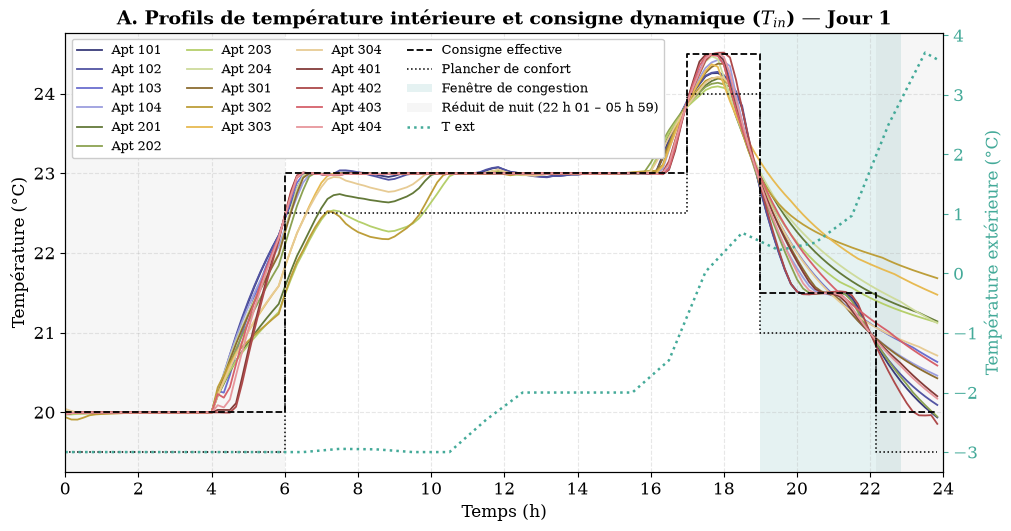

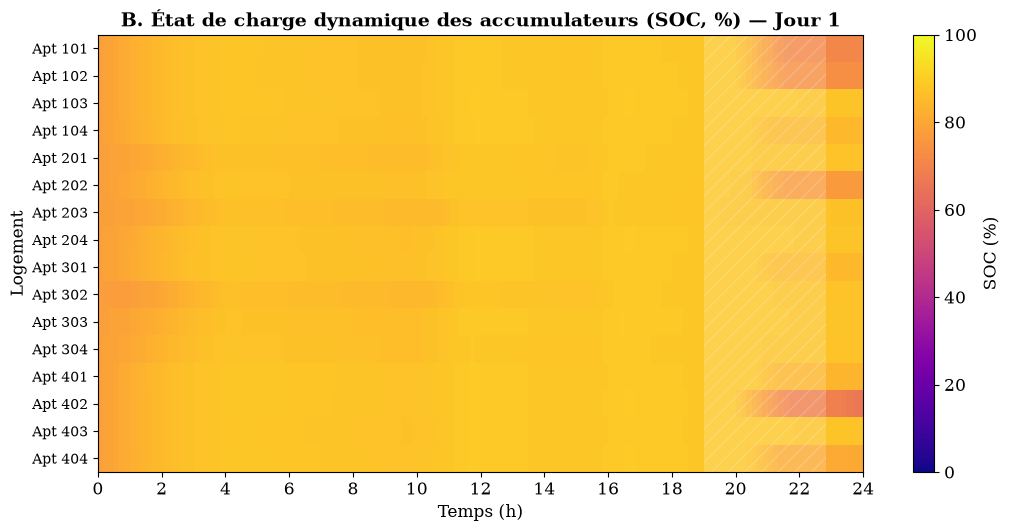

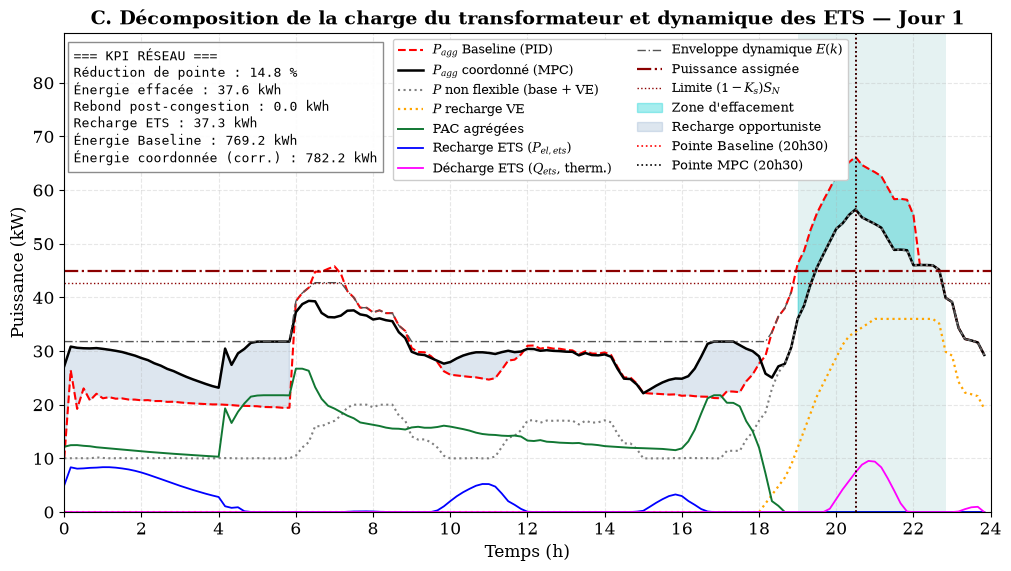

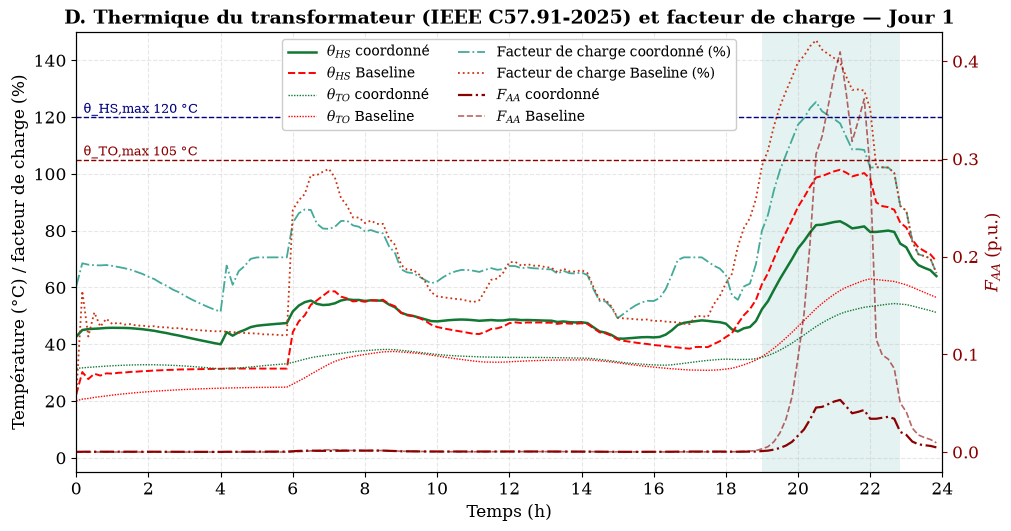

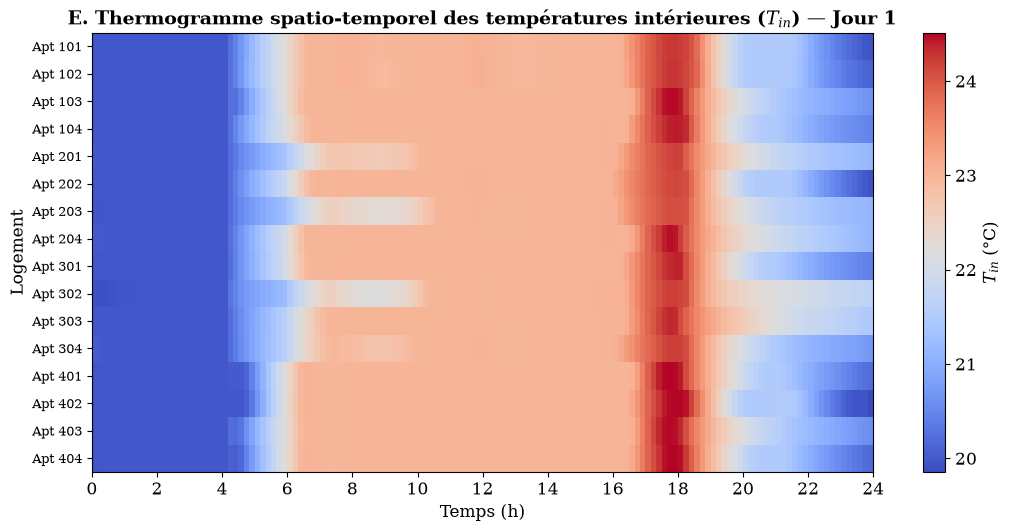

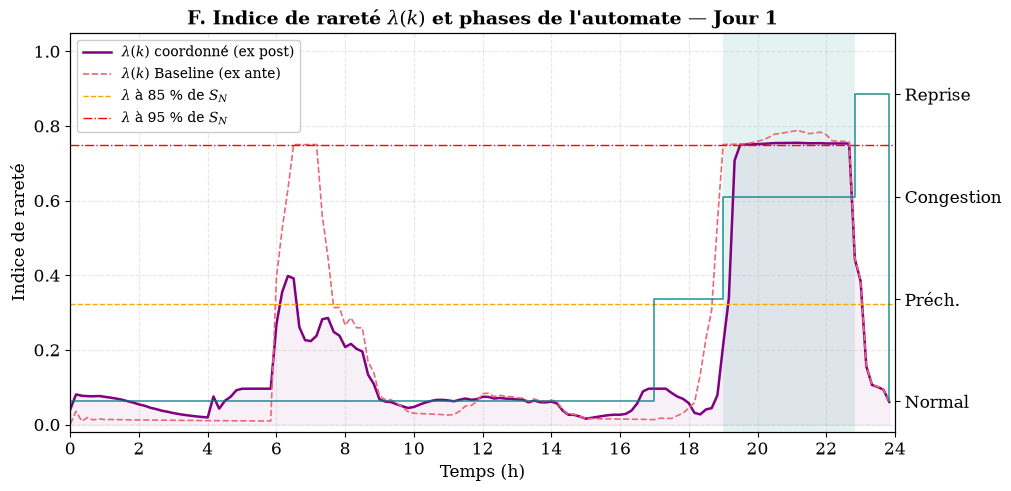

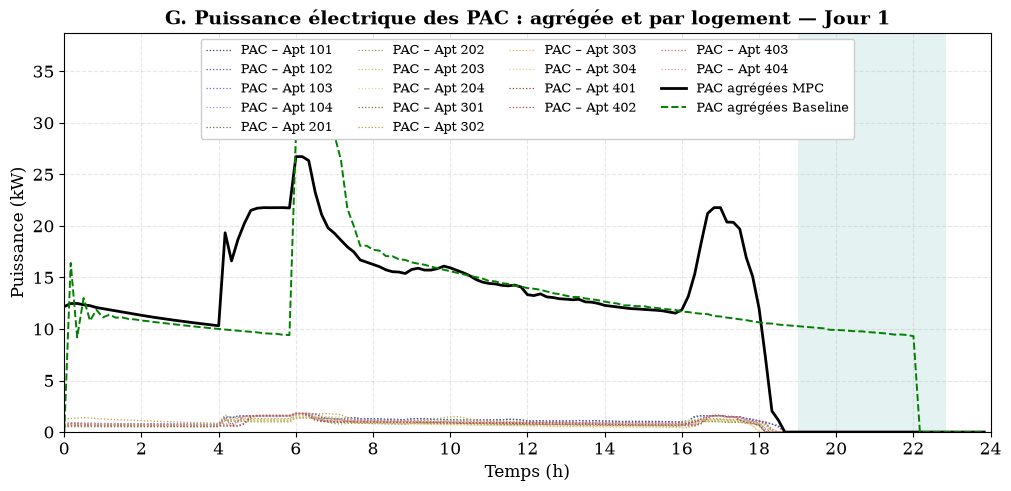

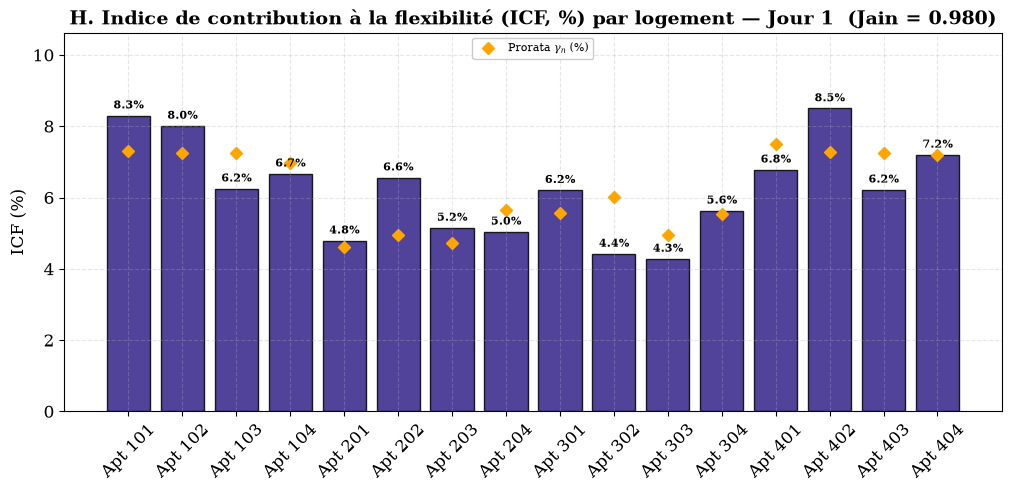

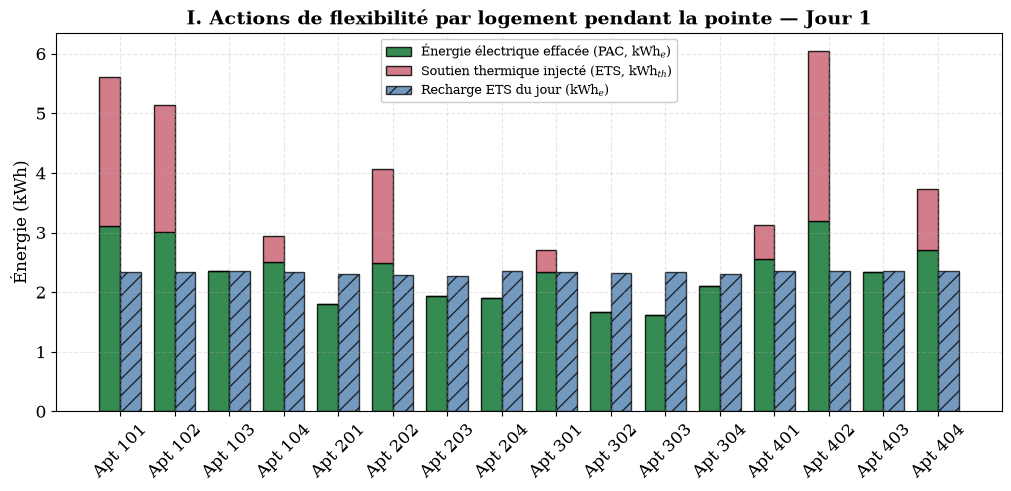

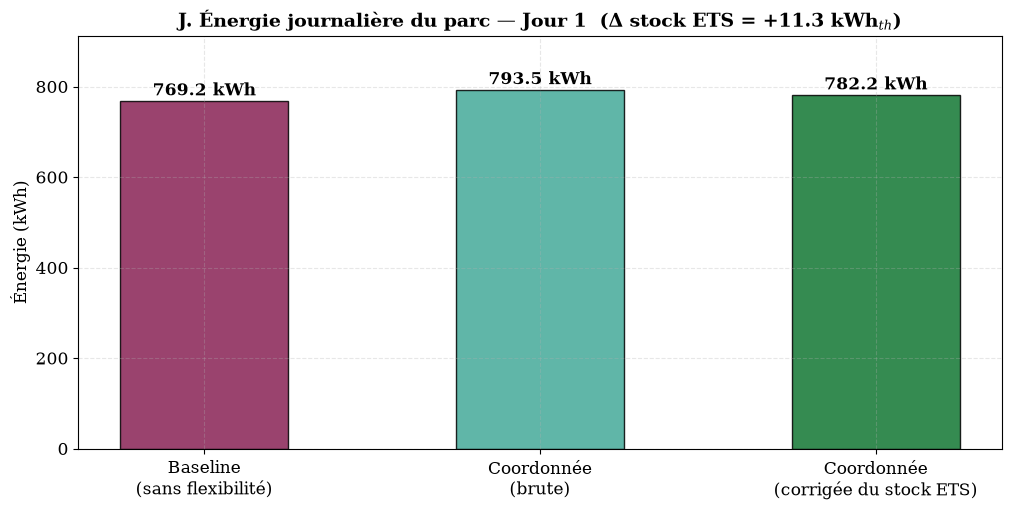

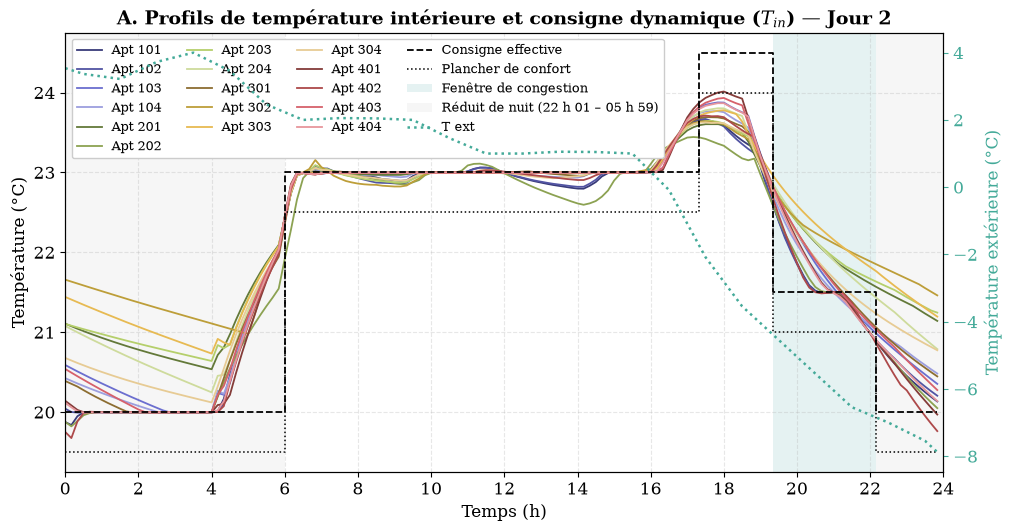

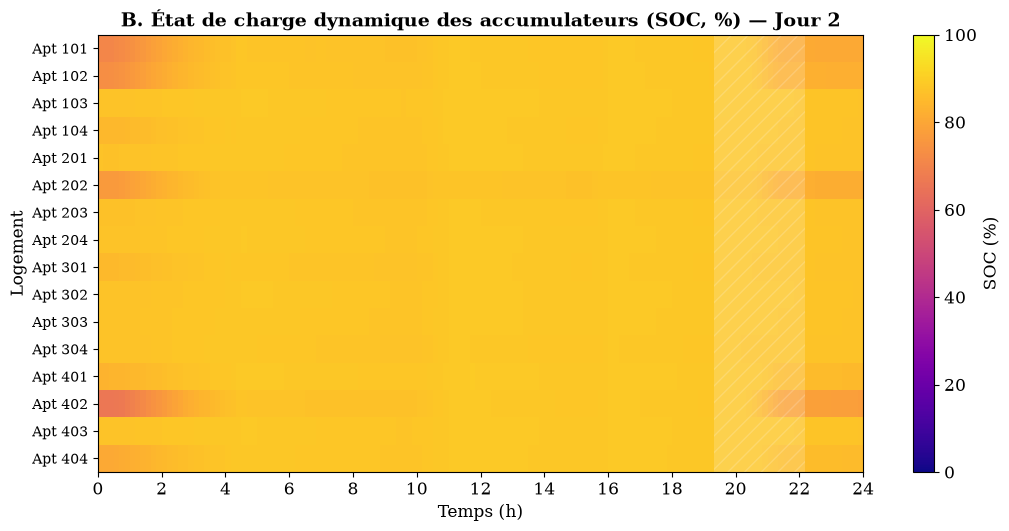

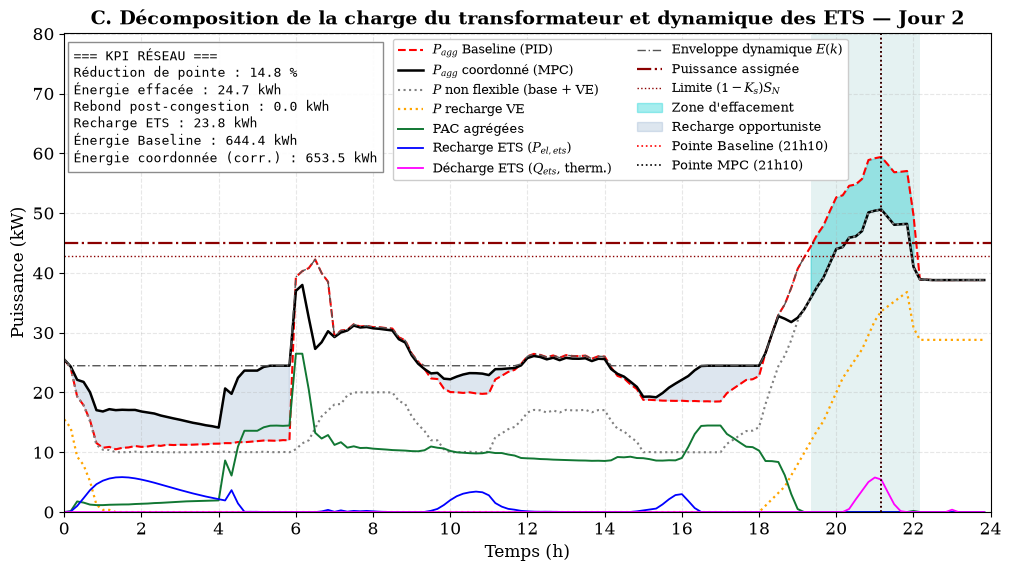

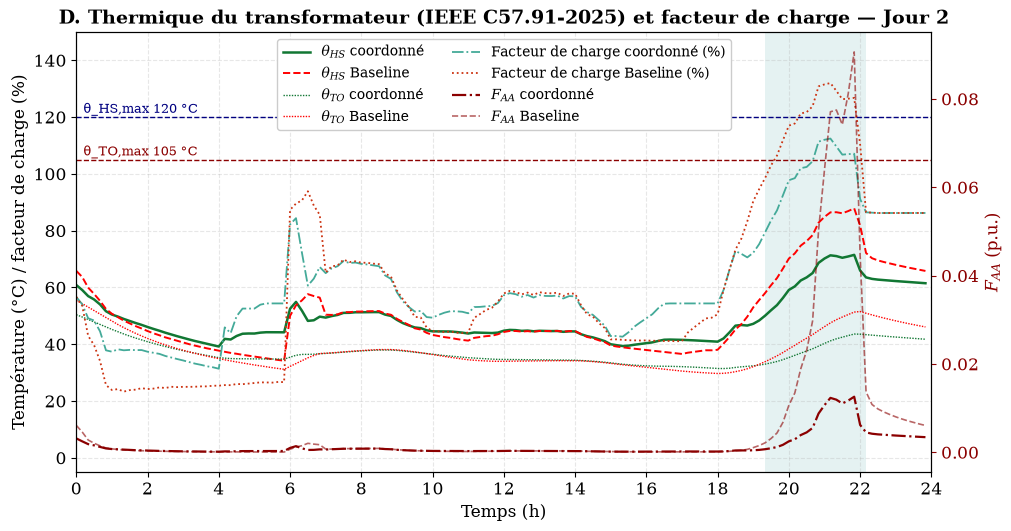

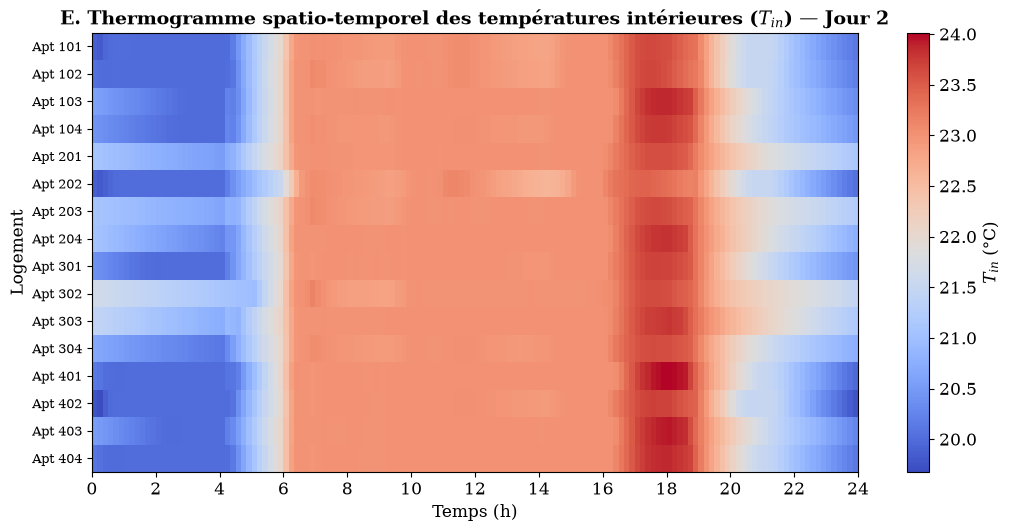

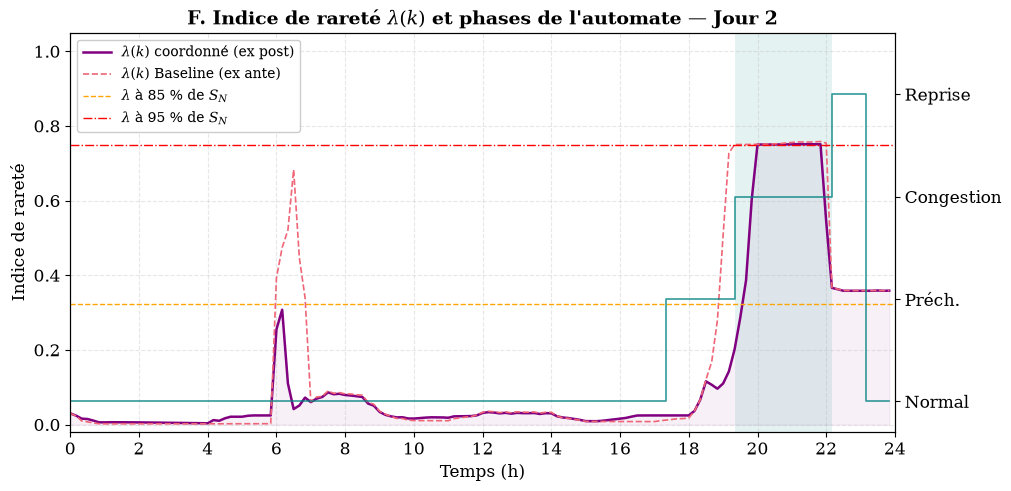

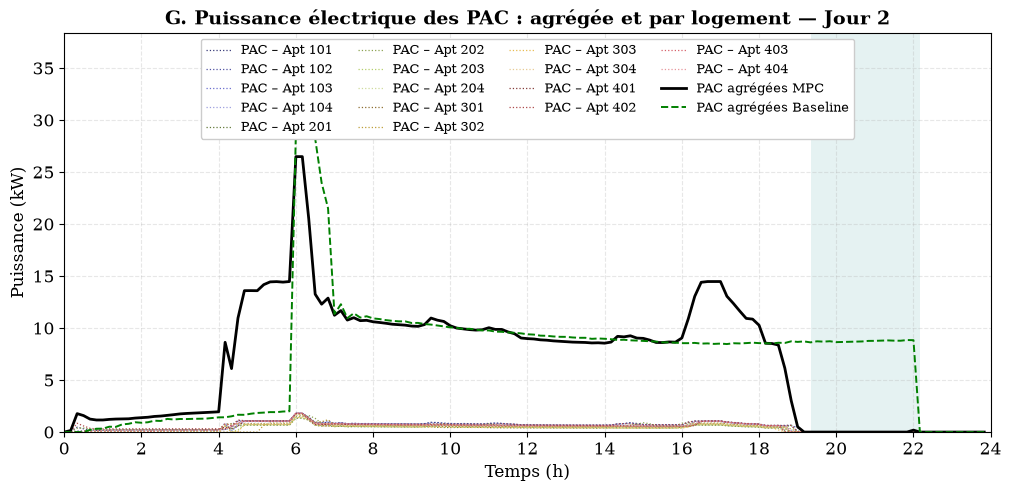

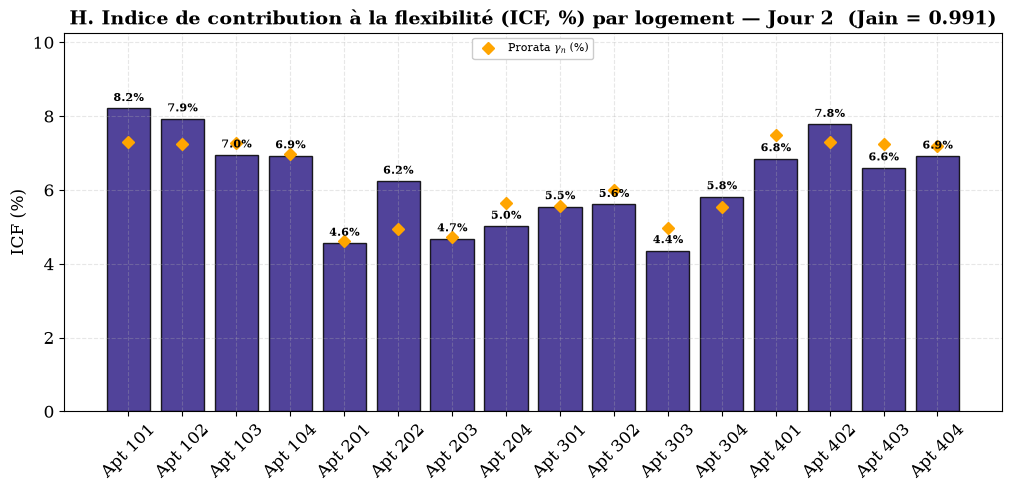

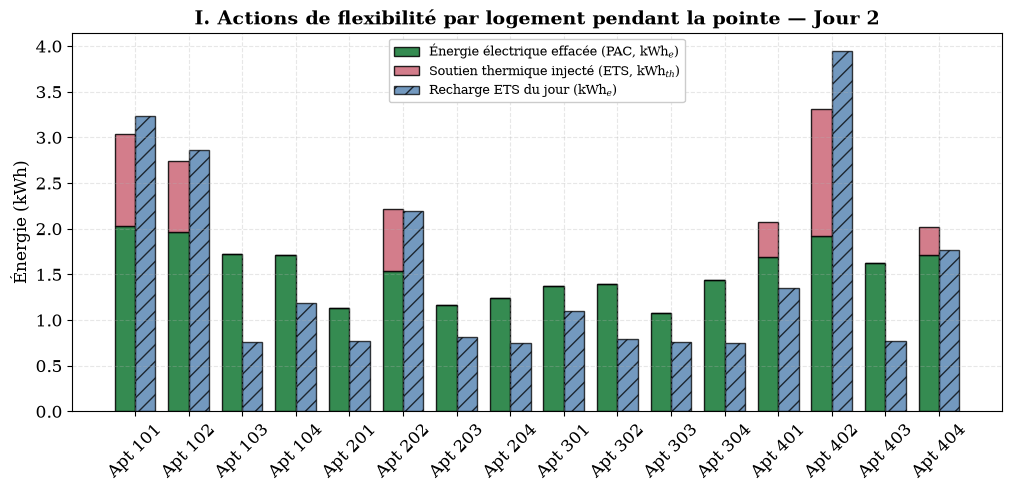

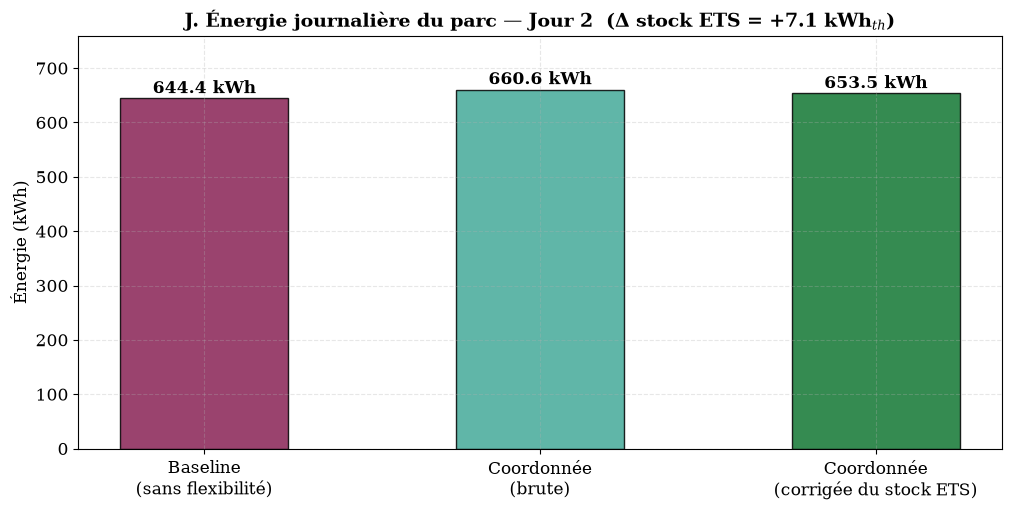

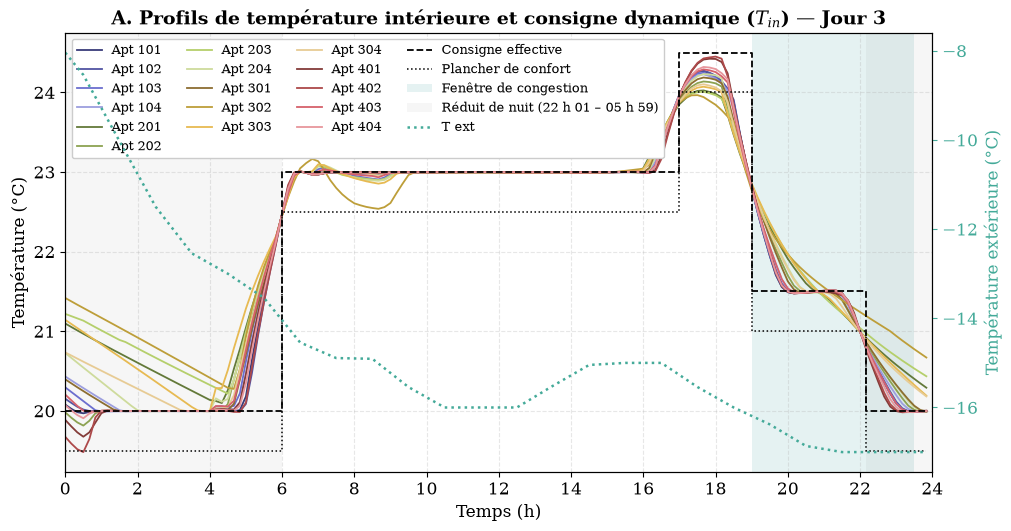

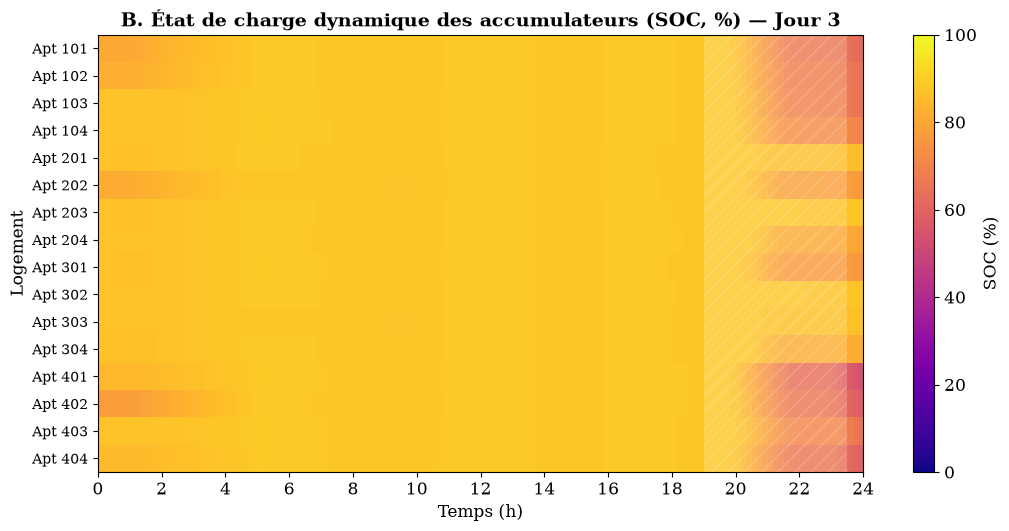

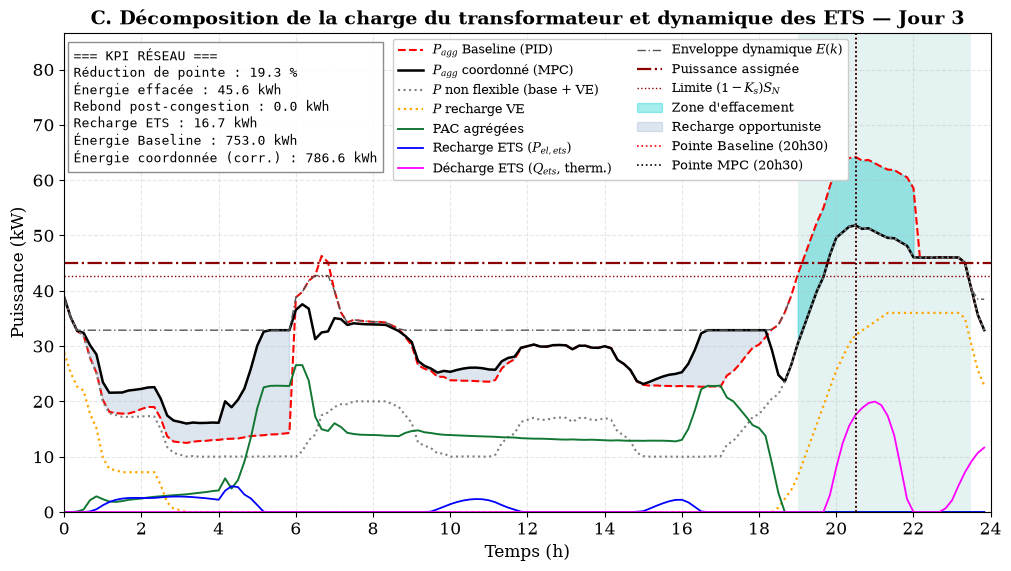

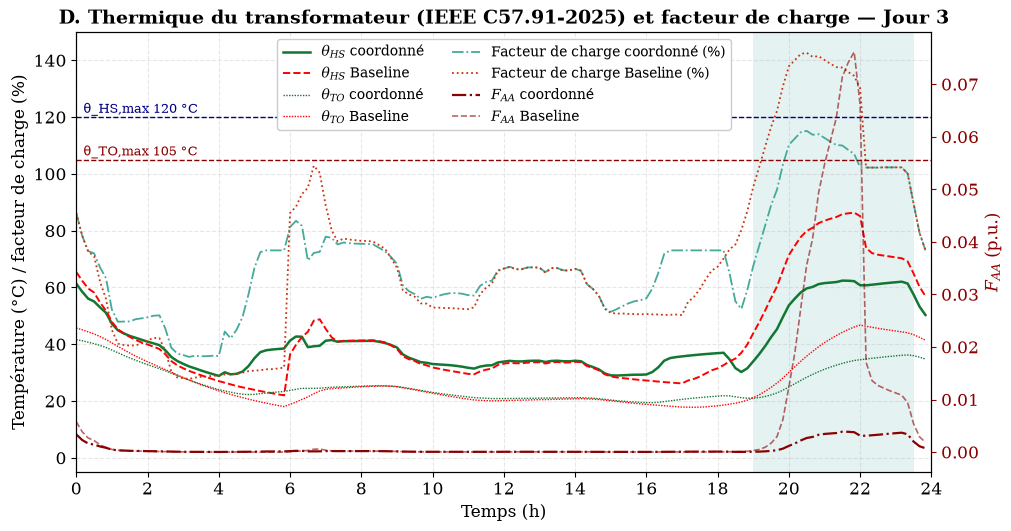

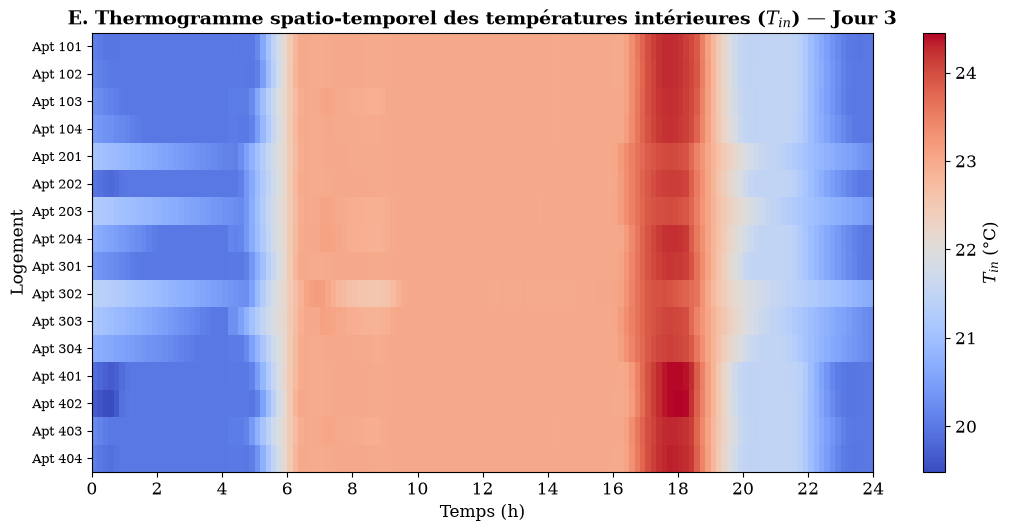

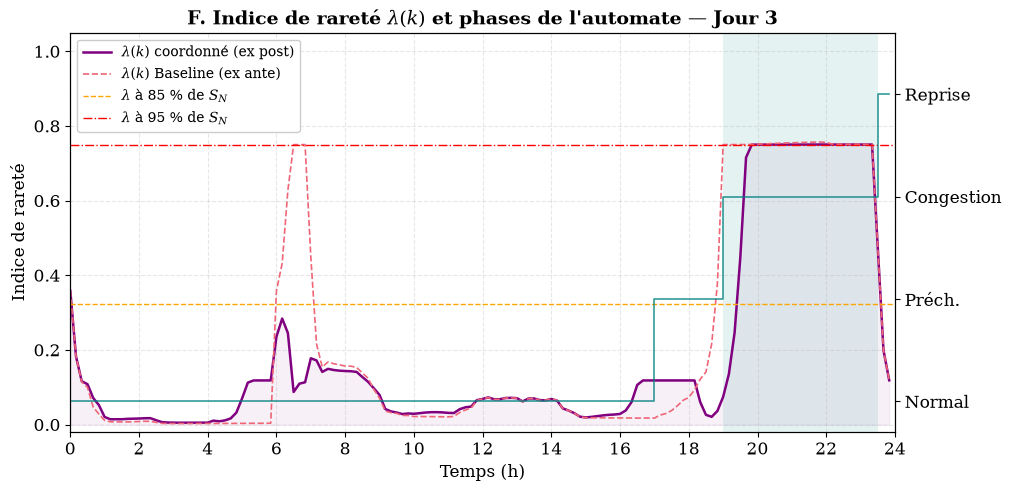

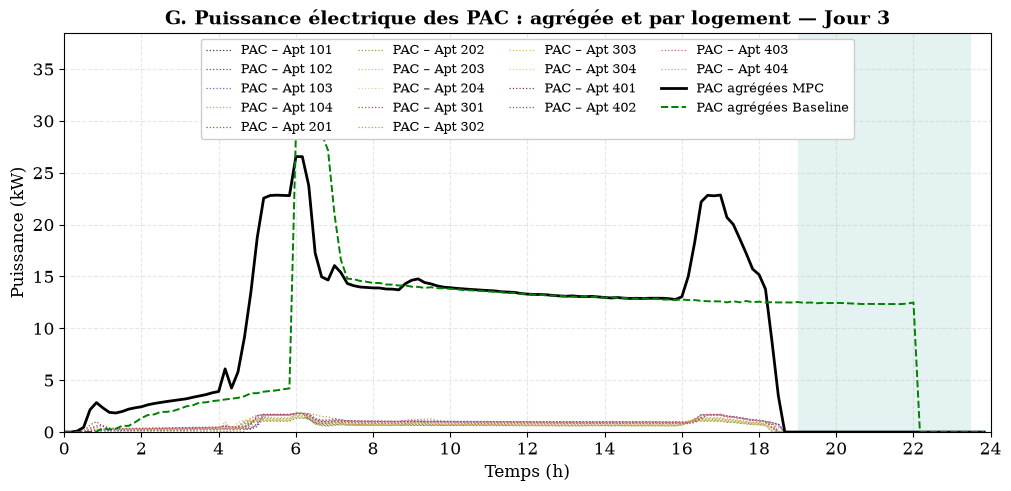

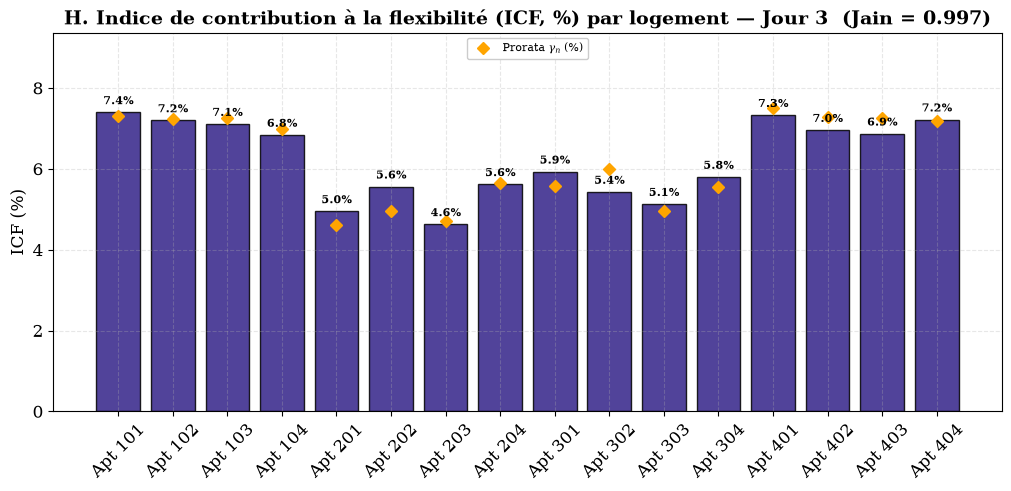

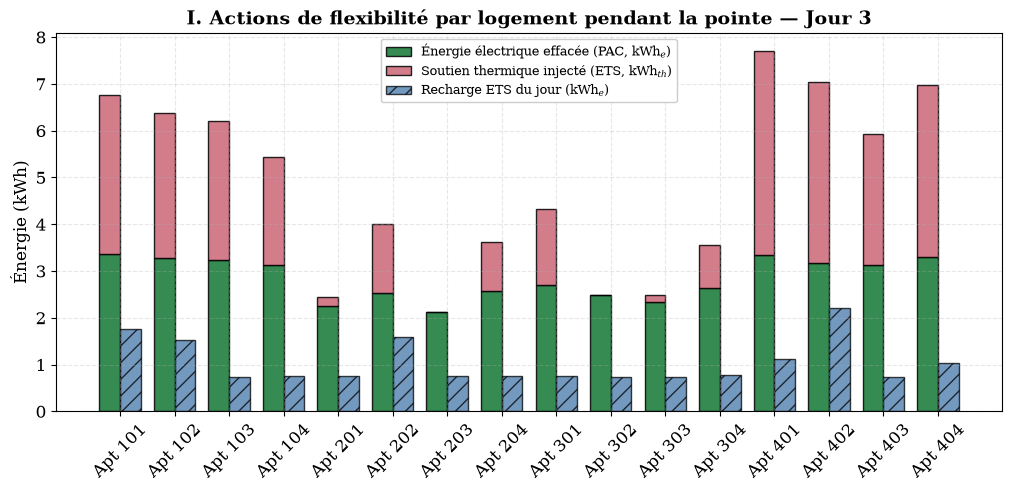

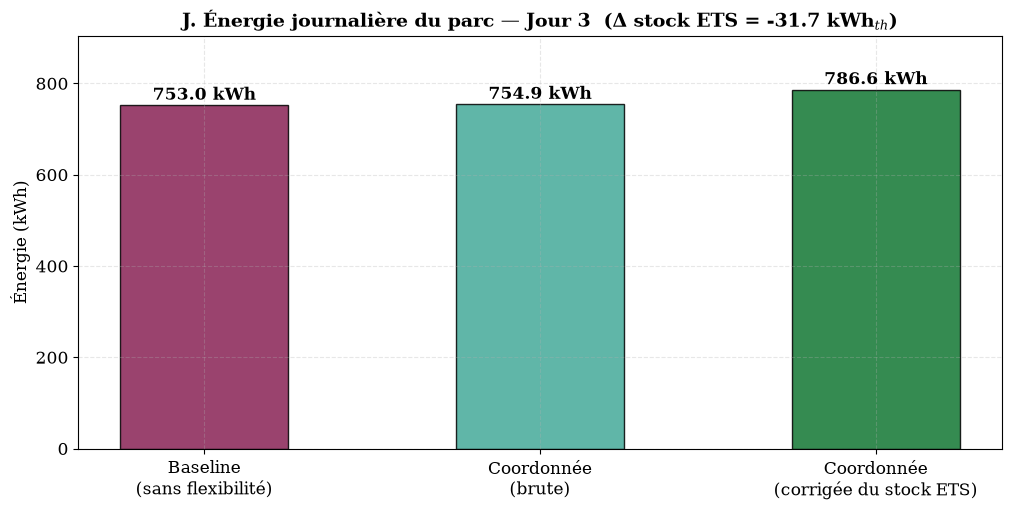

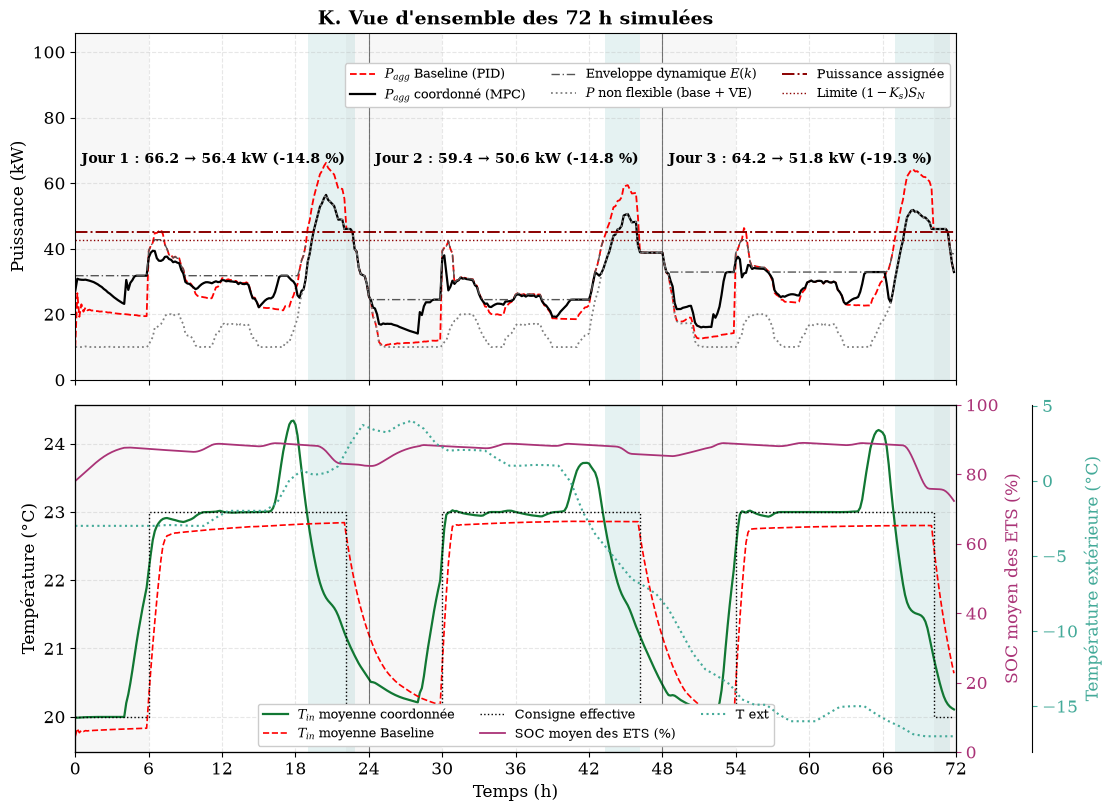

In [13]:
t0 = time.time()
sim = Simulateur_MPC(CONFIG)          # 1. chargement des données et des modèles
sim.simuler()                         # 2. Baseline + stratégie coordonnée + indicateurs de chaque jour
print("=" * 90); print(f" RAPPORT v1d — 72 h simulées en {time.time()-t0:.0f} s — mode d'enveloppe '{CONFIG['mode_enveloppe']}'")
print(" Niveaux de vallée L par période creuse : "
      + " ; ".join(f"{sim.t[a]:.1f}–{sim.t[b-1]:.1f} h : {L:.1f} kW (besoin {B:.0f} kWh)" for a, b, L, B in sim.L_seg))
print("=" * 90); print(" SYNTHÈSE DES 3 JOURS"); print(sim.synthese_jours.to_string(index=False))
for j in CONFIG["jours_analyse"]:     # 3. tableau IV détaillé de chaque jour
    print("\n" + "-" * 90 + f"\n TABLEAU IV — JOUR {j}\n" + "-" * 90)
    print(sim.tableau_IV_par_jour[j].to_string(index=False))
k = sim.kpi_resultats
print(f"\nSLSQP : {sim.n_echecs} échecs / {sim.n_appels} appels ({100*sim.n_echecs/sim.n_appels:.1f} %) | "
      f"{1000*np.mean(sim.t_calc):.0f} ms par appel | filtre de garde actif {sim.n_garde} pas")
for j in CONFIG["jours_analyse"]:     # 4. figures A–J de chaque jour
    sim.tracer_graphiques_publication(jour=j)
sim.tracer_vue_72h()                  # 5. figure K (72 h)
# Pour des figures en anglais sans relancer la simulation :
#   sim.c["langue_fig"] = "en"; [sim.tracer_graphiques_publication(jour=j, prefixe="v1d_EN") for j in (1, 2, 3)]
#   sim.tracer_vue_72h(prefixe="v1d_EN"); sim.c["langue_fig"] = "fr"